# Crop-JEPA · Stage A — controlled re-validation of vegetation-aware and multi-scale I-JEPA

This notebook runs **Stage A** of the research roadmap: a properly powered 2×2 factorial test of the two
Crop-JEPA modifications (vegetation-aware target placement × multi-scale target blocks) against original I-JEPA,
plus a random-init and a supervised baseline, with multiple seeds, multiple label draws, and paired statistics.

| Arm | Vegetation-aware targets | Multi-scale targets |
|---|---|---|
| `ijepa` | no | no |
| `veg` | yes | no |
| `ms` | no | yes |
| `veg_ms` | yes | yes |

**How to use it**
1. Edit only the *Quick configuration* cell below.
2. Run everything once with `RUN_MODE = "smoke"` (generated images, a few minutes). It checks the whole pipeline.
3. Point `DATA_ROOT` at your dataset, set `RUN_MODE = "benchmark"` to measure speed and memory on this machine.
4. Set `RUN_MODE = "full"` and run all cells. Re-running continues where it stopped: finished runs are skipped,
   unfinished runs resume from their last checkpoint.

Everything is saved under `OUTPUT_DIR`: splits, label draws, checkpoints, logs, per-run results, statistics, figures.
See the accompanying report for run instructions, design choices, debugging and how to read the results.

## 0. Quick configuration — the only cell you normally edit

In [1]:
RUN_MODE = "smoke"        # "smoke" = generated data, whole pipeline in minutes · "benchmark" = measure speed only · "full" = real runs
PROFILE = "auto"          # "auto" or one of: "laptop_4gb", "laptop_4gb_vits", "kaggle_t4", "kaggle_t4_fast", "kaggle_p100", "big_gpu", "cpu_debug"
DATA_ROOT = None          # folder with class sub-folders, or with train/ (val/) test/ sub-folders. None = auto-detect on Kaggle
METADATA_CSV = None       # optional CSV with columns path,label[,group][,split]; paths may be relative to DATA_ROOT
OUTPUT_DIR = None         # None = ./outputs on a laptop, /kaggle/working/outputs on Kaggle
RESUME_FROM_DIR = None    # Kaggle: a previous session's outputs attached as input, e.g. "/kaggle/input/<notebook-output>/outputs"

ARMS = ["ijepa", "veg", "ms", "veg_ms"]     # the Stage A factorial
BASELINES = ["random_init", "supervised"]   # add "dinov2" if internet access is available (frozen DINOv2 ViT-S/14 reference)
SEEDS = [0, 1, 2]                           # pretraining seeds (smoke mode uses [0, 1])
SHARD_ID, NUM_SHARDS = 0, 1                 # split the run queue across machines / teammates' accounts
OVERRIDES = {}                              # e.g. {"epochs": 300} — applied on top of the hardware profile
ALLOW_PROFILE_CHANGE = False                # keep False: all arms of one comparison must run on the same profile
ZIP_CHECKPOINTS = False                     # include *.pt checkpoints in the downloadable results zip

## 1. Environment check
Detects Kaggle vs laptop, the GPU, its memory and which number formats it supports.

In [2]:
import os, sys, json, time, math, random, hashlib, shutil, platform, copy, warnings, traceback, zipfile, contextlib, datetime
from dataclasses import dataclass, asdict
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps

SESSION_START = time.time()
_missing = []
try:
    import torchvision
    from torchvision.ops import roi_align
except Exception:
    _missing.append("torchvision")
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
except Exception:
    _missing.append("scikit-learn")
try:
    from scipy.stats import wilcoxon
except Exception:
    _missing.append("scipy")
try:
    import matplotlib.pyplot as plt
except Exception:
    _missing.append("matplotlib")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install with: pip install {' '.join(_missing)}")
try:
    from IPython.display import display
except Exception:
    display = print

IS_KAGGLE = os.path.isdir("/kaggle/input") or bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
IS_WINDOWS = platform.system() == "Windows"
HAS_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda:0" if HAS_CUDA else "cpu")


def describe_gpu():
    if not HAS_CUDA:
        return {"name": "CPU only", "vram_gb": 0.0, "capability": "-", "bf16": False, "n_gpus": 0}
    p = torch.cuda.get_device_properties(0)
    return {"name": p.name, "vram_gb": round(p.total_memory / 1024**3, 2), "capability": f"{p.major}.{p.minor}",
            "bf16": p.major >= 8, "n_gpus": torch.cuda.device_count()}


GPU = describe_gpu()
if HAS_CUDA:
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    try:  # catches "no kernel image is available" early (old GPUs vs new PyTorch builds)
        _ = (torch.ones(8, 8, device=DEVICE) @ torch.ones(8, 8, device=DEVICE)).sum().item()
    except Exception as e:
        raise RuntimeError(f"CUDA is visible but kernels do not run on {GPU['name']}: {e}. "
                           "On Kaggle switch the accelerator to 'GPU T4 x2'; on a laptop reinstall PyTorch for your CUDA version.")
    if float(GPU["capability"]) < 7.0:
        print("WARNING: Pascal-class GPU (e.g. P100): no tensor cores, mixed precision gives little; prefer a T4 on Kaggle.")

print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Platform: {platform.system()} | Kaggle: {IS_KAGGLE} | Device: {DEVICE}")
print(f"GPU: {GPU['name']} | VRAM {GPU['vram_gb']} GB | compute capability {GPU['capability']} | bf16: {GPU['bf16']} | GPUs visible: {GPU['n_gpus']}")
if IS_WINDOWS:
    print("Windows detected: this notebook uses no DataLoader worker processes, so it runs unchanged on Windows.")

Python 3.13.0 | PyTorch 2.11.0+cpu | torchvision 0.26.0+cpu
Platform: Windows | Kaggle: False | Device: cpu
GPU: CPU only | VRAM 0.0 GB | compute capability - | bf16: False | GPUs visible: 0
Windows detected: this notebook uses no DataLoader worker processes, so it runs unchanged on Windows.


## 2. Hardware profiles and experiment configuration
A profile fixes model size, resolution, batch size and number format for one kind of machine.
All arms and seeds of one comparison must use the same profile (enforced via `locked_profile.json`).

In [3]:
@dataclass
class Config:
    profile: str = "laptop_4gb"
    # model (ViT-Tiny/16 by default)
    img_size: int = 160
    patch_size: int = 16
    enc_dim: int = 192
    enc_depth: int = 12
    enc_heads: int = 3
    pred_dim: int = 128
    pred_depth: int = 4
    pred_heads: int = 4
    grad_ckpt: bool = False
    # optimisation (I-JEPA style schedules)
    batch_size: int = 128
    epochs: int = 200
    warmup_frac: float = 0.1
    blr: float = 5e-4               # peak lr per 256 images; peak = blr * batch / 256
    min_lr: float = 1e-6
    wd_start: float = 0.04
    wd_end: float = 0.4
    ema_start: float = 0.996
    ema_end: float = 1.0
    grad_clip: float = 3.0
    precision: str = "bf16"         # "bf16" (Ampere+), "fp16" (T4, with loss scaling), "fp32"
    # masking
    num_targets: int = 4
    target_scale: tuple = (0.15, 0.2)
    target_aspect: tuple = (0.75, 1.5)
    context_scale: tuple = (0.85, 1.0)
    min_context: int = 10
    ms_scales: tuple = ((0.04, 0.08), (0.10, 0.14), (0.17, 0.23), (0.28, 0.36))  # mean total 0.70 = 4 x 0.175 (token-matched)
    veg_index: str = "chromatic"    # "chromatic" (2g-r-b on r=R/(R+G+B)) or "raw" (2G-R-B, as in the original notebook)
    veg_tau: float = 0.5            # softmax temperature over z-scored block greenness
    veg_eps: float = 0.2            # share of uniform exploration
    # augmentation
    crop_scale: tuple = (0.3, 1.0)
    hflip: bool = True
    # data
    cache_res: int = 256
    val_frac: float = 0.15
    test_frac: float = 0.15
    split_seed: int = 42
    dedup_hamming: int = 4
    # evaluation
    shots: tuple = (1, 5, 10, 25, 50, 100)
    percents: tuple = (10, 100)
    n_draws: int = 5
    probe_C: tuple = (0.001, 0.01, 0.1, 1.0, 10.0)
    knn_k: int = 20
    knn_t: float = 0.07
    eval_batch: int = 256
    # supervised baseline
    sup_epochs: int = 100
    sup_blr: float = 5e-4
    sup_wd: float = 0.05
    label_smoothing: float = 0.1
    sup_eval_every: int = 5
    sup_regimes: tuple = ("10pct", "100pct")
    # monitoring, checkpoints, statistics
    monitor_n: int = 512
    knn_monitor_every: int = 10     # online k-NN check on validation images (labels used for monitoring only)
    knn_monitor_train: int = 2000
    ckpt_every: int = 5
    max_session_hours: float = 1e9
    eval_reserve_min: float = 15.0
    bootstrap_B: int = 1000
    low_label_regimes: tuple = ("5shot", "10shot", "25shot")


VIT_S = dict(enc_dim=384, enc_heads=6, pred_dim=192, pred_depth=6, pred_heads=6)
PROFILES = {
    "cpu_debug":       dict(img_size=64, patch_size=8, enc_dim=96, enc_depth=4, enc_heads=3, pred_dim=64, pred_depth=2,
                            pred_heads=2, batch_size=32, epochs=6, blr=2e-3, sup_blr=2e-3, precision="fp32", cache_res=72,
                            min_context=4, shots=(1, 5, 10), percents=(10, 100), n_draws=2, sup_epochs=25, sup_eval_every=5,
                            knn_monitor_every=2,
                            monitor_n=64, ckpt_every=1, bootstrap_B=200, eval_batch=64,
                            low_label_regimes=("1shot", "5shot", "10shot")),
    "laptop_4gb":      dict(),                                                   # ViT-Tiny/16 @160, bf16
    "laptop_4gb_vits": dict(img_size=224, batch_size=64, **VIT_S),               # ViT-S/16 @224, bf16, slow but fits
    "kaggle_t4":       dict(img_size=224, batch_size=128, precision="fp16", max_session_hours=11.0, **VIT_S),
    "kaggle_t4_fast":  dict(precision="fp16", max_session_hours=11.0),           # ViT-Tiny/16 @160 on a T4
    "kaggle_p100":     dict(img_size=224, batch_size=128, precision="fp32", max_session_hours=11.0, **VIT_S),
    "big_gpu":         dict(img_size=224, batch_size=128, precision="bf16" if GPU["bf16"] else "fp16", **VIT_S),
}


def auto_profile():
    if not HAS_CUDA:
        return "cpu_debug"
    name, vram = GPU["name"].lower(), GPU["vram_gb"]
    if vram < 6:
        return "laptop_4gb"
    if "t4" in name:
        return "kaggle_t4"
    if "p100" in name:
        return "kaggle_p100"
    return "big_gpu"


def hardware_precision():
    if not HAS_CUDA:
        return "fp32"
    return "bf16" if GPU["bf16"] else ("fp16" if float(GPU["capability"]) >= 7.0 else "fp32")


assert RUN_MODE in ("smoke", "benchmark", "full"), RUN_MODE
profile_name = auto_profile() if PROFILE == "auto" else PROFILE
if RUN_MODE == "smoke":
    cfg = Config(**{**PROFILES["cpu_debug"], "precision": hardware_precision()})
    cfg.profile = "smoke"
    SEEDS_RUN = [0, 1]
else:
    if profile_name not in PROFILES:
        raise ValueError(f"Unknown profile {profile_name}; choose from {list(PROFILES)}")
    cfg = Config(**{**PROFILES[profile_name], **OVERRIDES})
    cfg.profile = profile_name
    SEEDS_RUN = list(SEEDS)
if cfg.precision == "bf16" and not GPU["bf16"]:
    print("bf16 not supported here; switching to", hardware_precision())
    cfg.precision = hardware_precision()
if IS_KAGGLE and cfg.max_session_hours > 11.5:
    cfg.max_session_hours = 11.0
assert cfg.img_size % cfg.patch_size == 0 and cfg.enc_dim % cfg.enc_heads == 0 and cfg.pred_dim % cfg.pred_heads == 0
assert cfg.enc_dim % 4 == 0 and cfg.pred_dim % 4 == 0, "sin-cos position embeddings need dims divisible by 4"

BASE_OUT = Path(OUTPUT_DIR) if OUTPUT_DIR else (Path("/kaggle/working/outputs") if IS_KAGGLE else Path("./outputs"))
OUT = BASE_OUT / "smoke" if RUN_MODE == "smoke" else BASE_OUT
for sub in ["runs", "cache", "figures", "stats"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

if RESUME_FROM_DIR and Path(RESUME_FROM_DIR).exists() and RUN_MODE != "smoke":
    copied = 0
    for src in Path(RESUME_FROM_DIR).rglob("*"):
        dst = OUT / src.relative_to(RESUME_FROM_DIR)
        if src.is_file() and not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)
            copied += 1
    print(f"Resumed from {RESUME_FROM_DIR}: copied {copied} files into {OUT}")

grid = cfg.img_size // cfg.patch_size
print(f"Mode: {RUN_MODE} | profile: {cfg.profile} | precision: {cfg.precision} | output: {OUT.resolve()}")
print(f"Encoder: ViT dim {cfg.enc_dim} x depth {cfg.enc_depth}, patch {cfg.patch_size}, {cfg.img_size}px -> {grid}x{grid} tokens | "
      f"predictor dim {cfg.pred_dim} x depth {cfg.pred_depth} | batch {cfg.batch_size} | epochs {cfg.epochs}")
print(f"Seeds: {SEEDS_RUN} | arms: {ARMS} | baselines: {BASELINES} | shard {SHARD_ID}/{NUM_SHARDS}")

Mode: smoke | profile: smoke | precision: fp32 | output: C:\Users\vrain\OneDrive\Desktop\vjepa\try 1\outputs\smoke
Encoder: ViT dim 96 x depth 4, patch 8, 64px -> 8x8 tokens | predictor dim 64 x depth 2 | batch 32 | epochs 6
Seeds: [0, 1] | arms: ['ijepa', 'veg', 'ms', 'veg_ms'] | baselines: ['random_init', 'supervised'] | shard 0/1


## 3. Utilities: seeding, atomic saving, time budget

In [4]:
class TimeBudgetExceeded(Exception):
    """Raised when the session is about to hit its time limit; progress is checkpointed first."""


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if HAS_CUDA:
        torch.cuda.manual_seed_all(seed)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


def save_json(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def atomic_torch_save(obj, path):
    """Write to a temp file then rename, so a crash mid-save never corrupts the previous checkpoint."""
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


TRAIN_KEYS = ["img_size", "patch_size", "enc_dim", "enc_depth", "enc_heads", "pred_dim", "pred_depth", "pred_heads",
              "batch_size", "epochs", "warmup_frac", "blr", "min_lr", "wd_start", "wd_end", "ema_start", "ema_end",
              "grad_clip", "precision", "num_targets", "target_scale", "target_aspect", "context_scale", "min_context",
              "ms_scales", "veg_index", "veg_tau", "veg_eps", "crop_scale", "hflip", "cache_res"]


def config_hash(cfg, arm, seed):
    d = {k: getattr(cfg, k) for k in TRAIN_KEYS}
    d.update(arm=arm, seed=seed)
    return hashlib.sha1(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:12]


def hours_left():
    return cfg.max_session_hours - (time.time() - SESSION_START) / 3600


def budget_str():
    return "no session limit" if cfg.max_session_hours >= 1e6 else f"{hours_left():.1f} h left in session budget"


def get_rng_state():
    st = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if HAS_CUDA:
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st


def set_rng_state(st):
    random.setstate(st["python"])
    np.random.set_state(st["numpy"])
    torch.set_rng_state(st["torch"])
    if HAS_CUDA and "cuda" in st:
        torch.cuda.set_rng_state_all(st["cuda"])


def autocast_ctx():
    if DEVICE.type != "cuda" or cfg.precision == "fp32":
        return contextlib.nullcontext()
    return torch.autocast("cuda", dtype=torch.bfloat16 if cfg.precision == "bf16" else torch.float16)


def free_memory():
    import gc
    gc.collect()
    if HAS_CUDA:
        torch.cuda.empty_cache()

## 4. Data: discovery, hygiene checks, group-aware splits, image cache, label draws
Images are read once, centre-cropped to `cache_res`, and stored as one uint8 array. Training then crops and
flips on the GPU, so no DataLoader worker processes are needed (important on Windows and on a 4 GB laptop).

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val", "validation": "val",
                 "test": "test", "testing": "test"}


def make_synthetic_dataset(root, n_classes=6, per_class=50, res=96, seed=0):
    """Generated 'crop' images (green striped patches on soil) with site groups and 3 planted duplicates.
    Used only by the smoke test, to exercise every code path without real data."""
    root = Path(root)
    if (root / "metadata.csv").exists():
        return root / "metadata.csv"
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:res, 0:res] / res
    rows = []
    for c in range(n_classes):
        d = root / f"crop_{c}"
        d.mkdir(parents=True, exist_ok=True)
        theta, freq = np.pi * c / n_classes, 3 + 2 * (c % 3)
        for i in range(per_class):
            img = np.ones((res, res, 3)) * (np.array([0.45, 0.35, 0.25]) + rng.normal(0, 0.03, 3))
            img += rng.normal(0, 0.04, (res, res, 3))
            stripes = np.sin(2 * np.pi * freq * (xx * np.cos(theta) + yy * np.sin(theta)) + rng.uniform(0, 6.28)) > (0.3 if c % 2 else -0.3)
            cx, cy, r = rng.uniform(0.3, 0.7), rng.uniform(0.3, 0.7), rng.uniform(0.3, 0.5)
            veg = stripes & (((xx - cx) ** 2 + (yy - cy) ** 2) < r ** 2)
            img[veg] = np.array([0.15, 0.50 + 0.08 * (c % 2), 0.12]) + rng.normal(0, 0.05, (veg.sum(), 3))
            path = d / f"img_{i:03d}.png"
            Image.fromarray((np.clip(img, 0, 1) * 255).astype(np.uint8)).save(path)
            rows.append({"path": str(path.relative_to(root)), "label": f"crop_{c}", "group": f"site_{c}_{i // 3}"})
    for k in range(3):  # planted duplicates in different groups: the hygiene check must merge them
        src = root / rows[k * 7]["path"]
        dst = src.parent / f"dup_{k}.png"
        shutil.copy(src, dst)
        rows.append({"path": str(dst.relative_to(root)), "label": rows[k * 7]["label"], "group": f"dupgroup_{k}"})
    pd.DataFrame(rows).to_csv(root / "metadata.csv", index=False)
    return root / "metadata.csv"


def _has_images(folder, limit=50):
    try:
        for i, e in enumerate(os.scandir(folder)):
            if i > limit:
                break
            if e.is_file() and Path(e.name).suffix.lower() in IMG_EXT:
                return True
    except (PermissionError, FileNotFoundError):
        pass
    return False


def autodetect_data_root(base="/kaggle/input", max_depth=5):
    """Finds the shallowest folder whose sub-folders contain images (class folders or train/test folders)."""
    base = Path(base)
    if not base.exists():
        return None
    for depth in range(max_depth):
        for d in sorted(p for p in base.glob("/".join(["*"] * (depth + 1))) if p.is_dir()):
            subs = [s for s in d.iterdir() if s.is_dir()]
            names = {s.name.lower() for s in subs}
            if "train" in names and ("test" in names or "testing" in names):
                return d
            if sum(_has_images(s) for s in subs[:200]) >= 2:
                return d
    return None


def list_images(folder):
    return sorted(str(p) for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)


def discover_dataset(data_root, metadata_csv=None):
    data_root = Path(data_root) if data_root else None
    if metadata_csv:
        df = pd.read_csv(metadata_csv)
        if not {"path", "label"} <= set(df.columns):
            raise ValueError("METADATA_CSV needs at least the columns: path, label")
        base = data_root or Path(metadata_csv).parent
        df["path"] = [p if os.path.isabs(p) else str(base / p) for p in df["path"]]
    else:
        if data_root is None or not data_root.exists():
            raise FileNotFoundError(f"DATA_ROOT not found: {data_root}. Set DATA_ROOT in the configuration cell.")
        subdirs = {d.name.lower(): d for d in data_root.iterdir() if d.is_dir()}
        split_dirs = {SPLIT_ALIASES[k]: v for k, v in subdirs.items() if k in SPLIT_ALIASES}
        rows = []
        if "train" in split_dirs and "test" in split_dirs:
            for split, sd in split_dirs.items():
                for cd in sorted(x for x in sd.iterdir() if x.is_dir()):
                    rows += [dict(path=p, label=cd.name, split=split) for p in list_images(cd)]
        else:
            for cd in sorted(x for x in data_root.iterdir() if x.is_dir()):
                rows += [dict(path=p, label=cd.name) for p in list_images(cd)]
        df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("No images found. Expected class sub-folders (or train/test folders containing class sub-folders).")
    if "group" not in df.columns:
        print("NOTE: no 'group' column (site / field ID). Each image is treated as its own group; if several photos "
              "come from the same field, provide a METADATA_CSV with a group column to avoid train/test leakage.")
        df["group"] = df["path"]
    df["label"] = df["label"].astype(str)
    df["group"] = df["group"].astype(str)
    return df.reset_index(drop=True)


def _process_image(path, res):
    try:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            g = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
            bits = (g[:, 1:] > g[:, :-1]).flatten()
            h = int.from_bytes(np.packbits(bits).tobytes(), "big")
            arr = np.asarray(ImageOps.fit(im, (res, res), Image.BICUBIC), dtype=np.uint8)
        return arr, h, True
    except Exception:
        return None, 0, False


def build_cache(df, out_dir, res):
    cache_dir = Path(out_dir) / "cache"
    img_path, meta_path = cache_dir / f"images_{res}.npy", cache_dir / f"images_{res}.csv"
    if img_path.exists() and meta_path.exists():
        meta = pd.read_csv(meta_path, keep_default_na=False)
        if list(meta["path"]) == list(df["path"]):
            print(f"Image cache found: {img_path} ({len(meta)} images)")
            return img_path, meta
        print("Dataset file list changed: rebuilding the image cache.")
    n = len(df)
    tmp = cache_dir / f"images_{res}.tmp.npy"
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(n, res, res, 3))
    hashes, ok = [0] * n, np.zeros(n, dtype=bool)
    t0 = time.time()
    workers = min(8, (os.cpu_count() or 2))
    with ThreadPoolExecutor(workers) as ex:
        for i, (a, h, good) in enumerate(ex.map(lambda p: _process_image(p, res), df["path"])):
            if good:
                arr[i], hashes[i], ok[i] = a, h, True
            if (i + 1) % max(1, n // 10) == 0:
                print(f"  cached {i + 1}/{n} images ({time.time() - t0:.0f}s)")
    arr.flush()
    del arr
    os.replace(tmp, img_path)
    meta = df.copy()
    meta["dhash"] = [f"{h:016x}" for h in hashes]
    meta["ok"] = ok
    meta.to_csv(meta_path, index=False)
    print(f"Image cache written: {img_path} | unreadable images: {(~ok).sum()}")
    return img_path, meta


class UnionFind:
    def __init__(self, items):
        self.p = {x: x for x in items}

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[max(ra, rb)] = min(ra, rb)


def hygiene_and_groups(meta, max_dist):
    """Finds exact and near-duplicate images (dHash Hamming distance <= max_dist) and merges their groups,
    so duplicates can never end up in different splits. Returns meta with a 'group_final' column and a report."""
    meta = meta[meta["ok"].astype(bool)].reset_index(drop=True).copy()
    n = len(meta)
    hashes = np.array([int(h, 16) for h in meta["dhash"]], dtype=np.uint64)
    uf_img = UnionFind(range(n))
    seen = {}
    for i, h in enumerate(hashes.tolist()):
        if h in seen:
            uf_img.union(seen[h], i)
        else:
            seen[h] = i
    near_checked = max_dist > 0 and n <= 60000
    if near_checked:
        b = hashes.view(np.uint8).reshape(n, 8)
        lut = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
        chunk = max(1, int(2e7 // max(n, 1)))
        for s in range(0, n, chunk):
            dist = lut[b[s:s + chunk, None, :] ^ b[None, :, :]].sum(-1, dtype=np.int32)
            ii, jj = np.nonzero(dist <= max_dist)
            for i, j in zip(ii + s, jj):
                if j > i:
                    uf_img.union(int(i), int(j))
    clusters = {}
    for i in range(n):
        clusters.setdefault(uf_img.find(i), []).append(i)
    dup_clusters = [c for c in clusters.values() if len(c) > 1]
    uf_grp = UnionFind(meta["group"].unique().tolist())
    for c in dup_clusters:
        g = meta["group"].iloc[c].tolist()
        for x in g[1:]:
            uf_grp.union(g[0], x)
    meta["group_final"] = [uf_grp.find(g) for g in meta["group"]]
    conflicting = [c for c in dup_clusters if meta["label"].iloc[c].nunique() > 1]
    report = {"images_ok": n, "duplicate_clusters": len(dup_clusters), "images_in_duplicate_clusters": int(sum(len(c) for c in dup_clusters)),
              "duplicate_clusters_with_conflicting_labels": len(conflicting), "near_duplicate_check": near_checked,
              "groups_before": int(meta["group"].nunique()), "groups_after": int(meta["group_final"].nunique())}
    return meta, report


def group_stratified_split(meta, val_frac, test_frac, seed, carve_from=None):
    """Assigns whole groups to splits, class by class, so class proportions are roughly kept and no group
    (site / field / duplicate cluster) spans two splits. With carve_from='train', only a validation split is
    carved out of the existing train split."""
    rng = np.random.default_rng(seed)
    pool = meta if carve_from is None else meta[meta["split"] == carve_from]
    g = pool.groupby("group_final").agg(label=("label", lambda s: s.mode().iloc[0]), size=("label", "size")).reset_index()
    order = [("test", test_frac), ("val", val_frac)] if carve_from is None else [("val", val_frac)]
    assign = {}
    for lab, sub in g.groupby("label"):
        sub = sub.iloc[rng.permutation(len(sub))]
        if len(sub) < 3:  # too few groups to split this class: keep it in train only
            assign.update({gid: "train" for gid in sub["group_final"]})
            continue
        total = sub["size"].sum()
        quota = {name: int(round(frac * total)) for name, frac in order}
        filled = {name: 0 for name, _ in order}
        labs = []
        for gid, size in zip(sub["group_final"], sub["size"]):
            dest = "train"
            for name, _ in order:
                if filled[name] < quota[name]:
                    dest = name
                    filled[name] += size
                    break
            assign[gid] = dest
            labs.append((gid, dest))
        if all(d != "train" for _, d in labs):  # guarantee at least one training group per class
            assign[labs[-1][0]] = "train"
    out = meta.copy()
    if carve_from is None:
        out["split"] = out["group_final"].map(assign).fillna("train")
    else:
        m = out["split"] == carve_from
        out.loc[m, "split"] = out.loc[m, "group_final"].map(assign).fillna(carve_from)
    return out


def make_or_load_splits(meta, out_dir):
    path = Path(out_dir) / "splits.csv"
    if path.exists():
        s = pd.read_csv(path, keep_default_na=False)
        if sorted(s["path"]) != sorted(meta["path"]):
            raise RuntimeError(f"{path} exists but the dataset's file list differs. Splits are never silently "
                               "re-made: delete splits.csv (and runs/) deliberately if the dataset really changed.")
        print(f"Splits loaded from {path}")
        return s
    if "split" in meta.columns and meta["split"].astype(str).isin(["train", "val", "test"]).all():
        s = meta.copy()
        s["split"] = s["split"].astype(str)
        if not (s["split"] == "val").any():
            s = group_stratified_split(s, cfg.val_frac / (1 - cfg.test_frac), 0.0, cfg.split_seed, carve_from="train")
        leak = s.groupby("group_final")["split"].nunique()
        if (leak > 1).any():
            print(f"WARNING: {(leak > 1).sum()} groups (duplicates or same site) span the predefined splits — the "
                  "predefined test set leaks. Consider re-splitting by removing the train/test folder structure.")
        print("Using the dataset's predefined train/test split (validation carved from train if missing).")
    else:
        s = group_stratified_split(meta, cfg.val_frac, cfg.test_frac, cfg.split_seed)
    classes = sorted(s["label"].unique())
    s["label_idx"] = s["label"].map({c: i for i, c in enumerate(classes)})
    s.to_csv(path, index=False)
    print(f"Splits written to {path}")
    return s


def make_or_load_draws(y_train, n_classes, out_dir, seed=1234):
    """Fixed label subsets per regime: k images per class (k-shot) or p% per class; saved so every arm and seed
    is evaluated on exactly the same labelled images."""
    path = Path(out_dir) / "label_draws.json"
    if path.exists():
        d = load_json(path)
        return {k: [np.array(x, dtype=np.int64) for x in v] for k, v in d.items()}
    rng = np.random.default_rng(seed)
    counts = np.bincount(y_train, minlength=n_classes)
    by_class = [np.where(y_train == c)[0] for c in range(n_classes)]
    draws = {}
    for k in cfg.shots:
        if (counts >= k).mean() < 0.8:
            print(f"  skipping {k}-shot: fewer than 80% of classes have {k} training images")
            continue
        draws[f"{k}shot"] = [np.concatenate([rng.choice(ix, min(k, len(ix)), replace=False) for ix in by_class if len(ix)])
                             for _ in range(cfg.n_draws)]
    for p in cfg.percents:
        if p >= 100:
            draws["100pct"] = [np.arange(len(y_train))]
        else:
            draws[f"{p}pct"] = [np.concatenate([rng.choice(ix, max(1, int(round(len(ix) * p / 100))), replace=False)
                                                for ix in by_class if len(ix)]) for _ in range(cfg.n_draws)]
    save_json({k: [x.tolist() for x in v] for k, v in draws.items()}, path)
    return draws


def regime_order(names):
    shots = sorted([n for n in names if n.endswith("shot")], key=lambda s: int(s[:-4]))
    pcts = sorted([n for n in names if n.endswith("pct")], key=lambda s: int(s[:-3]))
    return shots + pcts

### 4.1 Prepare the dataset (runs once; later sessions reuse the cache, splits and label draws)

In [6]:
if RUN_MODE == "smoke":
    METADATA_CSV_USED = make_synthetic_dataset(OUT / "synthetic_data")
    DATA_ROOT_USED = OUT / "synthetic_data"
else:
    METADATA_CSV_USED = METADATA_CSV
    DATA_ROOT_USED = Path(DATA_ROOT) if DATA_ROOT else (autodetect_data_root() if IS_KAGGLE else None)
    if DATA_ROOT_USED is None and not METADATA_CSV_USED:
        raise FileNotFoundError("Set DATA_ROOT (or METADATA_CSV) in the configuration cell. On Kaggle, attach the dataset via 'Add Data'.")
    print("Data root:", DATA_ROOT_USED)

raw = discover_dataset(DATA_ROOT_USED, METADATA_CSV_USED)
cache_path, cache_meta = build_cache(raw, OUT, cfg.cache_res)
meta_ok, hygiene = hygiene_and_groups(cache_meta, cfg.dedup_hamming)
save_json(hygiene, OUT / "stats" / "hygiene_report.json")
splits = make_or_load_splits(meta_ok, OUT)

# map split rows back to rows of the image cache
row_of_path = {p: i for i, p in enumerate(cache_meta["path"])}
splits["cache_row"] = splits["path"].map(row_of_path)
CLASSES = sorted(splits["label"].unique())
K = len(CLASSES)
ROWS = {s: splits.loc[splits["split"] == s, "cache_row"].to_numpy(np.int64) for s in ["train", "val", "test"]}
Y = {s: splits.loc[splits["split"] == s, "label_idx"].to_numpy(np.int64) for s in ["train", "val", "test"]}
Y_ALL = np.full(len(cache_meta), -1, dtype=np.int64)
for s in ROWS:
    Y_ALL[ROWS[s]] = Y[s]
DRAWS = make_or_load_draws(Y["train"], K, OUT)
REGIMES = regime_order(list(DRAWS))
np.save(OUT / "stats" / "y_test.npy", Y["test"])

print("Hygiene:", hygiene)
summary = splits.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
print(f"{K} classes | train {len(ROWS['train'])} | val {len(ROWS['val'])} | test {len(ROWS['test'])} | chance = {100 / K:.1f}%")
display(summary)
print("Label regimes:", {r: len(DRAWS[r]) for r in REGIMES})

  cached 30/303 images (0s)
  cached 60/303 images (0s)
  cached 90/303 images (0s)
  cached 120/303 images (0s)
  cached 150/303 images (0s)
  cached 180/303 images (0s)
  cached 210/303 images (0s)


  cached 240/303 images (0s)
  cached 270/303 images (0s)
  cached 300/303 images (0s)
Image cache written: outputs\smoke\cache\images_72.npy | unreadable images: 0
Splits written to outputs\smoke\splits.csv
Hygiene: {'images_ok': 303, 'duplicate_clusters': 3, 'images_in_duplicate_clusters': 6, 'duplicate_clusters_with_conflicting_labels': 0, 'near_duplicate_check': True, 'groups_before': 105, 'groups_after': 102}
6 classes | train 199 | val 52 | test 52 | chance = 16.7%


split,train,val,test
label,,,
crop_0,36,8,9
crop_1,33,9,8
crop_2,33,9,8
crop_3,32,9,9
crop_4,33,8,9
crop_5,32,9,9


Label regimes: {'1shot': 2, '5shot': 2, '10shot': 2, '10pct': 2, '100pct': 1}


## 5. GPU data pipeline
Batches are taken from the uint8 cache, moved to the GPU, then random-resized-cropped and flipped on the GPU
with `roi_align`. Vegetation scores are computed from these un-normalised [0, 1] pixels.

In [7]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def normalize(x01):
    return (x01 - MEAN.to(x01)) / STD.to(x01)


def _ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 1e9
    except Exception:
        try:
            return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
        except Exception:
            return 8.0


class CachedImages:
    def __init__(self, path):
        arr = np.load(path, mmap_mode="r")
        self.in_ram = arr.nbytes / 1e9 < 0.35 * _ram_gb()
        self.arr = np.ascontiguousarray(arr) if self.in_ram else arr
        print(f"Image cache: {arr.shape}, {arr.nbytes / 1e9:.2f} GB, {'loaded into RAM' if self.in_ram else 'memory-mapped from disk'}")

    def fetch(self, idx):
        order = np.argsort(idx, kind="stable")
        data = self.arr[idx[order]]
        out = np.empty_like(data)
        out[order] = data
        return torch.from_numpy(out)


def to_device_float(u8):
    if DEVICE.type == "cuda":
        u8 = u8.pin_memory().to(DEVICE, non_blocking=True)
    return u8.permute(0, 3, 1, 2).float().div_(255.0)


def random_resized_crop(x, out_size, scale, gen, hflip=True, ratio=(3 / 4, 4 / 3)):
    b, _, h, w = x.shape
    dev = x.device
    area = torch.empty(b, device=dev).uniform_(scale[0], scale[1], generator=gen) * h * w
    ar = torch.exp(torch.empty(b, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1]), generator=gen))
    cw = torch.sqrt(area * ar).clamp(8, w)
    ch = torch.sqrt(area / ar).clamp(8, h)
    x0 = torch.rand(b, device=dev, generator=gen) * (w - cw)
    y0 = torch.rand(b, device=dev, generator=gen) * (h - ch)
    boxes = torch.stack([torch.arange(b, device=dev, dtype=x.dtype), x0, y0, x0 + cw, y0 + ch], 1)
    out = roi_align(x, boxes, (out_size, out_size), spatial_scale=1.0, sampling_ratio=2, aligned=True)
    if hflip:
        flip = torch.rand(b, device=dev, generator=gen) < 0.5
        out = torch.where(flip.view(b, 1, 1, 1), out.flip(3), out)
    return out


class GPULoader:
    """Yields (images in [0,1] on DEVICE, cache rows). Deterministic given (seed, epoch): every arm with the same
    seed sees the same images in the same order with the same crops, which makes arm comparisons paired."""

    def __init__(self, cache, rows, batch_size, train, out_size, seed=0, drop_last=True, crop_scale=None):
        self.cache, self.rows, self.train, self.out_size, self.seed = cache, np.asarray(rows), train, out_size, seed
        self.bs = min(batch_size, len(self.rows))
        self.drop_last = drop_last and train
        self.crop_scale = crop_scale or cfg.crop_scale
        self.epoch = 0

    def set_epoch(self, e):
        self.epoch = e

    def __len__(self):
        n = len(self.rows)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def __iter__(self):
        rows = np.random.default_rng(self.seed * 100003 + self.epoch).permutation(self.rows) if self.train else self.rows
        gen = torch.Generator(device=DEVICE)
        gen.manual_seed(self.seed * 7919 + self.epoch)
        for b in range(len(self)):
            idx = rows[b * self.bs:(b + 1) * self.bs]
            x = to_device_float(self.cache.fetch(idx))
            if self.train:
                x = random_resized_crop(x, self.out_size, self.crop_scale, gen, cfg.hflip)
            elif x.shape[-1] != self.out_size:
                x = F.interpolate(x, size=(self.out_size, self.out_size), mode="bilinear", antialias=True, align_corners=False)
            yield x, idx


CACHE = CachedImages(cache_path)

Image cache: (303, 72, 72, 3), 0.00 GB, loaded into RAM


## 6. Model: ViT encoder and I-JEPA predictor
A compact ViT with fixed 2-D sin-cos position embeddings (as in I-JEPA) and PyTorch's fused attention.
No external model library is needed, which keeps the notebook identical on the laptop and on Kaggle.

In [8]:
def sincos_pos_embed(dim, gh, gw):
    gy, gx = np.meshgrid(np.arange(gh, dtype=np.float64), np.arange(gw, dtype=np.float64), indexing="ij")

    def emb1d(d, pos):
        omega = 1.0 / 10000 ** (np.arange(d // 2, dtype=np.float64) / (d / 2))
        out = np.einsum("m,d->md", pos.reshape(-1), omega)
        return np.concatenate([np.sin(out), np.cos(out)], 1)

    return torch.from_numpy(np.concatenate([emb1d(dim // 2, gy), emb1d(dim // 2, gx)], 1)).float().unsqueeze(0)


def gather_tokens(x, idx):
    return torch.gather(x, 1, idx.unsqueeze(-1).expand(-1, -1, x.size(-1)))


class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        b, n, c = x.shape
        q, k, v = self.qkv(x).reshape(b, n, 3, self.heads, c // self.heads).permute(2, 0, 3, 1, 4)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(b, n, c))


class MLP(nn.Module):
    def __init__(self, dim, ratio=4):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, dim * ratio), nn.GELU(), nn.Linear(dim * ratio, dim)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class Block(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(dim, eps=1e-6), Attention(dim, heads)
        self.norm2, self.mlp = nn.LayerNorm(dim, eps=1e-6), MLP(dim)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


def _init_weights(m):
    if isinstance(m, (nn.Linear, nn.Conv2d)):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.LayerNorm):
        nn.init.ones_(m.weight)
        nn.init.zeros_(m.bias)


def _rescale_blocks(blocks):  # I-JEPA's depth-dependent rescaling of residual projections
    for i, blk in enumerate(blocks):
        blk.attn.proj.weight.data.div_(math.sqrt(2.0 * (i + 1)))
        blk.mlp.fc2.weight.data.div_(math.sqrt(2.0 * (i + 1)))


class ViT(nn.Module):
    def __init__(self, img_size, patch, dim, depth, heads, grad_ckpt=False):
        super().__init__()
        self.grid, self.grad_ckpt, self.dim = img_size // patch, grad_ckpt, dim
        self.patch_embed = nn.Conv2d(3, dim, patch, patch)
        self.register_buffer("pos_embed", sincos_pos_embed(dim, self.grid, self.grid), persistent=False)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        self.apply(_init_weights)
        _rescale_blocks(self.blocks)

    def forward(self, x, keep_idx=None):
        t = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        if keep_idx is not None:
            t = gather_tokens(t, keep_idx)
        for blk in self.blocks:
            if self.grad_ckpt and self.training and torch.is_grad_enabled():
                t = torch.utils.checkpoint.checkpoint(blk, t, use_reentrant=False)
            else:
                t = blk(t)
        return self.norm(t)


class Predictor(nn.Module):
    def __init__(self, grid, enc_dim, dim, depth, heads):
        super().__init__()
        self.embed = nn.Linear(enc_dim, dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.register_buffer("pos_embed", sincos_pos_embed(dim, grid, grid), persistent=False)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        self.proj = nn.Linear(dim, enc_dim)
        self.apply(_init_weights)
        nn.init.trunc_normal_(self.mask_token, std=0.02)
        _rescale_blocks(self.blocks)

    def forward(self, ctx, ctx_idx, tgt_idx):
        b = ctx.shape[0]
        pos = self.pos_embed.expand(b, -1, -1)
        x = self.embed(ctx) + gather_tokens(pos, ctx_idx)
        m = self.mask_token.expand(b, tgt_idx.shape[1], -1) + gather_tokens(pos, tgt_idx)
        z = torch.cat([x, m], 1)
        for blk in self.blocks:
            z = blk(z)
        return self.proj(self.norm(z[:, -tgt_idx.shape[1]:]))


class SupervisedViT(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.encoder = ViT(cfg.img_size, cfg.patch_size, cfg.enc_dim, cfg.enc_depth, cfg.enc_heads, cfg.grad_ckpt)
        self.head = nn.Linear(cfg.enc_dim, n_classes)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.head(self.encoder(x).mean(1))


def make_encoder():
    return ViT(cfg.img_size, cfg.patch_size, cfg.enc_dim, cfg.enc_depth, cfg.enc_heads, cfg.grad_ckpt)


_e = make_encoder()
print(f"Encoder parameters: {sum(p.numel() for p in _e.parameters()) / 1e6:.2f} M")
del _e

Encoder parameters: 0.47 M


## 7. Target selection: I-JEPA multi-block, multi-scale, vegetation-aware
* **Baseline:** 4 target blocks, scale 0.15–0.20 of the image, aspect 0.75–1.5; one context block (scale 0.85–1.0)
  with the targets removed. Block sizes are shared across the batch, positions are per image.
* **Multi-scale:** the 4 targets use scales 0.04–0.08, 0.10–0.14, 0.17–0.23, 0.28–0.36. Their mean total area equals
  the baseline's, so the number of predicted tokens is matched across arms (logged every epoch to verify).
* **Vegetation-aware:** target positions are sampled from a softmax over z-scored block greenness (ExG on chromatic
  coordinates by default), mixed with `veg_eps` uniform exploration, instead of uniformly.

In [9]:
def veg_patch_scores(x01, patch, kind="chromatic"):
    r, g, b = x01[:, 0].float(), x01[:, 1].float(), x01[:, 2].float()
    exg = (2 * g - r - b) / (r + g + b + 1e-6) if kind == "chromatic" else (2 * g - r - b)
    return F.avg_pool2d(exg.unsqueeze(1), patch).squeeze(1)  # (B, grid, grid)


class MaskGenerator:
    def __init__(self, arm, seed):
        self.gh = self.gw = cfg.img_size // cfg.patch_size
        self.n = self.gh * self.gw
        self.multiscale = arm in ("ms", "veg_ms")
        self.veg = arm in ("veg", "veg_ms")
        self.cpu_gen = torch.Generator().manual_seed(seed * 31 + 1)
        self.dev_gen = torch.Generator(device=DEVICE)
        self.dev_gen.manual_seed(seed * 31 + 2)
        self.rows = torch.arange(self.gh, device=DEVICE)
        self.cols = torch.arange(self.gw, device=DEVICE)

    def state(self):
        return {"cpu": self.cpu_gen.get_state(), "dev": self.dev_gen.get_state()}

    def load(self, st):
        self.cpu_gen.set_state(st["cpu"])
        self.dev_gen.set_state(st["dev"])

    def _size(self, scale, aspect):
        s = torch.empty(1).uniform_(scale[0], scale[1], generator=self.cpu_gen).item()
        a = math.exp(torch.empty(1).uniform_(math.log(aspect[0]), math.log(aspect[1]), generator=self.cpu_gen).item())
        area = s * self.n
        h = int(round(math.sqrt(area * a)))
        w = int(round(math.sqrt(area / a)))
        return min(max(h, 1), self.gh), min(max(w, 1), self.gw)

    def _positions(self, b, h, w, scores=None):
        nr, nc = self.gh - h + 1, self.gw - w + 1
        if scores is None or nr * nc == 1:
            r = torch.randint(0, nr, (b,), device=DEVICE, generator=self.dev_gen)
            c = torch.randint(0, nc, (b,), device=DEVICE, generator=self.dev_gen)
            return r, c
        bs = F.avg_pool2d(scores.unsqueeze(1), (h, w), stride=1).flatten(1)
        z = (bs - bs.mean(1, keepdim=True)) / (bs.std(1, keepdim=True, unbiased=False) + 1e-6)
        p = (1 - cfg.veg_eps) * torch.softmax(z / cfg.veg_tau, 1) + cfg.veg_eps / (nr * nc)
        flat = torch.multinomial(p, 1, generator=self.dev_gen).squeeze(1)
        return flat // nc, flat % nc

    def _mask(self, r, c, h, w):
        mr = (self.rows[None] >= r[:, None]) & (self.rows[None] < (r + h)[:, None])
        mc = (self.cols[None] >= c[:, None]) & (self.cols[None] < (c + w)[:, None])
        return (mr[:, :, None] & mc[:, None, :]).flatten(1)

    def _idx(self, r, c, h, w):
        off = (torch.arange(h, device=DEVICE)[:, None] * self.gw + torch.arange(w, device=DEVICE)[None]).flatten()
        return (r * self.gw + c)[:, None] + off[None]

    @torch.no_grad()
    def __call__(self, x01):
        b = x01.shape[0]
        scores = veg_patch_scores(x01, cfg.patch_size, cfg.veg_index) if self.veg else None
        tgt_idx, union = [], torch.zeros(b, self.n, dtype=torch.bool, device=DEVICE)
        for i in range(cfg.num_targets):
            scale = cfg.ms_scales[i % len(cfg.ms_scales)] if self.multiscale else cfg.target_scale
            h, w = self._size(scale, cfg.target_aspect)
            r, c = self._positions(b, h, w, scores)
            tgt_idx.append(self._idx(r, c, h, w))
            union |= self._mask(r, c, h, w)
        hc, wc = self._size(cfg.context_scale, (1.0, 1.0))
        ctx = torch.zeros(b, self.n, dtype=torch.bool, device=DEVICE)
        for _ in range(10):  # re-sample context blocks that keep too few tokens
            need = ctx.sum(1) < cfg.min_context
            if not need.any():
                break
            r, c = self._positions(b, hc, wc)
            ctx = torch.where(need[:, None], self._mask(r, c, hc, wc) & ~union, ctx)
        bad = ctx.sum(1) < cfg.min_context
        ctx[bad] = ~union[bad]                       # fall back to "everything except the targets"
        empty = ctx.sum(1) == 0
        ctx[empty] = True                            # degenerate case: allow all tokens
        n_keep = int(ctx.sum(1).min().item())
        noise = torch.rand(b, self.n, device=DEVICE, generator=self.dev_gen).masked_fill(~ctx, -1.0)
        ctx_idx = noise.topk(n_keep, dim=1).indices.sort(1).values
        return ctx_idx, tgt_idx, {"ctx_tokens": n_keep, "tgt_tokens": sum(t.shape[1] for t in tgt_idx)}

## 8. I-JEPA training with EMA target encoder, mixed precision, checkpoints and collapse monitors
Checkpoints (`last.pt`) are written atomically every `ckpt_every` epochs and when time runs out; re-running the
notebook resumes from them. Every epoch the target encoder's features on a fixed validation batch are checked for
collapse (RankMe effective rank, per-dimension spread of normalised features).

In [10]:
def param_groups(modules):
    decay, no_decay = [], []
    for m in modules:
        for n, p in m.named_parameters():
            if not p.requires_grad:
                continue
            (no_decay if p.ndim < 2 or "mask_token" in n else decay).append(p)
    return [{"params": decay, "weight_decay": cfg.wd_start, "apply_wd": True},
            {"params": no_decay, "weight_decay": 0.0, "apply_wd": False}]


def lr_at(step, total, peak):
    warm = max(1, int(cfg.warmup_frac * total))
    if step < warm:
        return peak * (step + 1) / warm
    t = (step - warm) / max(1, total - warm)
    return cfg.min_lr + 0.5 * (peak - cfg.min_lr) * (1 + math.cos(math.pi * t))


def cos_ramp(step, total, start, end):
    t = min(1.0, step / max(1, total))
    return end + (start - end) * 0.5 * (1 + math.cos(math.pi * t))


@torch.no_grad()
def representation_stats(encoder, rows, bs=128):
    was = encoder.training
    encoder.eval()
    feats = []
    for x01, _ in GPULoader(CACHE, rows, bs, train=False, out_size=cfg.img_size):
        with autocast_ctx():
            feats.append(encoder(normalize(x01)).mean(1).float())
    encoder.train(was)
    f = torch.cat(feats).cpu()
    sv = torch.linalg.svdvals(f - f.mean(0))  # centred, so a shared mean vector does not hide collapse
    p = sv / sv.sum() + 1e-7
    z = F.normalize(f, dim=1)
    return {"rankme": float(torch.exp(-(p * p.log()).sum())), "feat_std": float(z.std(0).mean()),
            "feat_norm": float(f.norm(dim=1).mean()), "top_sv_share": float(sv[0] / sv.sum())}


@torch.no_grad()
def online_knn_f1(encoder, train_rows, val_rows, bs=128):
    """Macro-F1 of a 20-NN classifier on validation images using training-image features: the standard SSL
    progress monitor. Labels are used only to watch training, never to choose checkpoints or settings."""
    if len(val_rows) == 0:
        return float("nan")
    was = encoder.training
    encoder.eval()
    feats = {}
    for name, rows in (("tr", train_rows), ("va", val_rows)):
        out = []
        for x01, _ in GPULoader(CACHE, rows, bs, train=False, out_size=cfg.img_size):
            with autocast_ctx():
                out.append(encoder(normalize(x01)).mean(1).float().cpu())
        feats[name] = torch.cat(out).numpy()
    encoder.train(was)
    ytr, yva = Y_ALL[train_rows], Y_ALL[val_rows]
    tr = F.normalize(torch.from_numpy(feats["tr"]), dim=1)
    va = F.normalize(torch.from_numpy(feats["va"]), dim=1)
    v, idx = (va @ tr.T).topk(min(20, len(tr)), dim=1)
    votes = torch.zeros(len(va), K).scatter_add_(1, torch.from_numpy(ytr)[idx], (v / cfg.knn_t).exp())
    return metrics_from_cm(confusion(yva, votes.argmax(1).numpy(), K))[0]["macro_f1"]


class JEPARun:
    def __init__(self, arm, seed, run_dir):
        self.arm, self.seed, self.dir = arm, seed, Path(run_dir)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.hash = config_hash(cfg, arm, seed)
        seed_everything(seed)  # same initial weights for every arm with this seed (paired design)
        self.ctx_enc = make_encoder().to(DEVICE)
        self.tgt_enc = copy.deepcopy(self.ctx_enc).eval()
        for p in self.tgt_enc.parameters():
            p.requires_grad_(False)
        self.pred = Predictor(cfg.img_size // cfg.patch_size, cfg.enc_dim, cfg.pred_dim, cfg.pred_depth, cfg.pred_heads).to(DEVICE)
        self.loader = GPULoader(CACHE, ROWS["train"], cfg.batch_size, train=True, out_size=cfg.img_size, seed=seed)
        self.total = cfg.epochs * len(self.loader)
        self.peak_lr = cfg.blr * self.loader.bs / 256
        self.opt = torch.optim.AdamW(param_groups([self.ctx_enc, self.pred]), lr=self.peak_lr)
        self.scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda" and cfg.precision == "fp16")
        self.maskgen = MaskGenerator(arm, seed)
        self.params = [p for m in (self.ctx_enc, self.pred) for p in m.parameters() if p.requires_grad]
        self.cparams = list(self.ctx_enc.parameters())
        self.tparams = list(self.tgt_enc.parameters())
        self.history, self.step, self.epochs_done = [], 0, 0
        self.monitor_rows = ROWS["val"][:cfg.monitor_n] if len(ROWS["val"]) else ROWS["train"][:cfg.monitor_n]
        self.knn_train_rows = ROWS["train"][np.random.default_rng(0).permutation(len(ROWS["train"]))[:cfg.knn_monitor_train]]

    def state(self):
        return {"ctx_enc": self.ctx_enc.state_dict(), "tgt_enc": self.tgt_enc.state_dict(), "pred": self.pred.state_dict(),
                "opt": self.opt.state_dict(), "scaler": self.scaler.state_dict(), "step": self.step,
                "epochs_done": self.epochs_done, "history": self.history, "cfg_hash": self.hash, "rng": get_rng_state(),
                "maskgen": self.maskgen.state(), "saved_at": datetime.datetime.now().isoformat()}

    def save(self):
        atomic_torch_save(self.state(), self.dir / "last.pt")

    def try_resume(self):
        ck = self.dir / "last.pt"
        if not ck.exists():
            return
        st = torch.load(ck, map_location=DEVICE, weights_only=False)
        if st["cfg_hash"] != self.hash:
            raise RuntimeError(f"{ck} was written with a different configuration (hash {st['cfg_hash']} vs {self.hash}). "
                               "Move that run folder away to start fresh, or restore the old settings.")
        self.ctx_enc.load_state_dict(st["ctx_enc"])
        self.tgt_enc.load_state_dict(st["tgt_enc"])
        self.pred.load_state_dict(st["pred"])
        self.opt.load_state_dict(st["opt"])
        self.scaler.load_state_dict(st["scaler"])
        self.step, self.epochs_done, self.history = st["step"], st["epochs_done"], st["history"]
        self.maskgen.load(st["maskgen"])
        set_rng_state(st["rng"])
        print(f"  resumed {self.dir.name} at epoch {self.epochs_done}/{cfg.epochs}")

    @torch.no_grad()
    def ema_update(self, m):
        torch._foreach_mul_(self.tparams, m)
        torch._foreach_add_(self.tparams, self.cparams, alpha=1 - m)

    def train_step(self, x01):
        lr = lr_at(self.step, self.total, self.peak_lr)
        wd = cos_ramp(self.step, self.total, cfg.wd_start, cfg.wd_end)
        m = cfg.ema_start + (cfg.ema_end - cfg.ema_start) * min(1.0, self.step / max(1, self.total))
        for g in self.opt.param_groups:
            g["lr"] = lr
            if g["apply_wd"]:
                g["weight_decay"] = wd
        ctx_idx, tgt_list, st = self.maskgen(x01)
        x = normalize(x01)
        with autocast_ctx():
            with torch.no_grad():
                h = self.tgt_enc(x)
                h = F.layer_norm(h.float(), (h.shape[-1],))
            z = self.ctx_enc(x, keep_idx=ctx_idx)
            num, den = 0.0, 0
            for t_idx in tgt_list:  # token-weighted loss over all predicted target tokens
                p = self.pred(z, ctx_idx, t_idx)
                t = gather_tokens(h, t_idx)
                num = num + F.smooth_l1_loss(p.float(), t, reduction="sum")
                den += t.numel()
            loss = num / den
        if not torch.isfinite(loss):
            self.opt.zero_grad(set_to_none=True)
            return None, st, (lr, wd, m)
        self.scaler.scale(loss).backward()
        if cfg.grad_clip:
            self.scaler.unscale_(self.opt)
            torch.nn.utils.clip_grad_norm_(self.params, cfg.grad_clip)
        self.scaler.step(self.opt)
        self.scaler.update()
        self.opt.zero_grad(set_to_none=True)
        self.ema_update(m)
        self.step += 1
        return loss.detach(), st, (lr, wd, m)

    def train(self):
        if (self.dir / "encoder_final.pt").exists():
            print(f"  {self.dir.name}: pretraining already finished")
            return
        self.try_resume()
        log_path = self.dir / "train_log.csv"
        print_every = max(1, cfg.epochs // 10)
        reserve_s = cfg.eval_reserve_min * 60
        for epoch in range(self.epochs_done, cfg.epochs):
            if self.history:
                avg = float(np.mean([r["epoch_time_s"] for r in self.history[-5:]]))
                if hours_left() * 3600 < 1.5 * avg + reserve_s:
                    self.save()
                    raise TimeBudgetExceeded(f"{self.dir.name}: stopped before epoch {epoch + 1}; checkpoint saved")
            self.loader.set_epoch(epoch)
            self.ctx_enc.train()
            self.pred.train()
            if HAS_CUDA:
                torch.cuda.reset_peak_memory_stats()
            t0, loss_sum, n_ok, n_bad, ctx_t, tgt_t = time.time(), torch.zeros((), device=DEVICE), 0, 0, [], []
            try:
                for x01, _ in self.loader:
                    loss, st, (lr, wd, m) = self.train_step(x01)
                    ctx_t.append(st["ctx_tokens"])
                    tgt_t.append(st["tgt_tokens"])
                    if loss is None:
                        n_bad += 1
                        if n_bad > 20:
                            self.save()
                            raise RuntimeError("More than 20 non-finite losses in one epoch: see the debugging section of the report.")
                        continue
                    loss_sum += loss
                    n_ok += 1
            except KeyboardInterrupt:
                self.save()
                print("Interrupted: checkpoint saved. Re-run to resume.")
                raise
            ep_time = time.time() - t0
            self.epochs_done = epoch + 1
            row = {"epoch": epoch + 1, "loss": float(loss_sum) / max(1, n_ok), "lr": lr, "wd": wd, "ema": m,
                   "epoch_time_s": ep_time, "imgs_per_s": n_ok * self.loader.bs / max(ep_time, 1e-6),
                   "peak_mem_gb": torch.cuda.max_memory_allocated() / 1e9 if HAS_CUDA else 0.0,
                   "ctx_tokens": float(np.mean(ctx_t)), "tgt_tokens": float(np.mean(tgt_t)), "nonfinite_steps": n_bad}
            row.update(representation_stats(self.tgt_enc, self.monitor_rows))
            do_knn = epoch == 0 or (epoch + 1) % cfg.knn_monitor_every == 0 or epoch + 1 == cfg.epochs
            row["knn_val_f1"] = online_knn_f1(self.tgt_enc, self.knn_train_rows, ROWS["val"]) if do_knn else float("nan")
            self.history.append(row)
            pd.DataFrame([row]).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
            if epoch == 0 or (epoch + 1) % print_every == 0 or epoch + 1 == cfg.epochs:
                knn_txt = f"val kNN-F1 {100 * row['knn_val_f1']:.1f}% " if row["knn_val_f1"] == row["knn_val_f1"] else ""
                print(f"  {self.dir.name} ep {epoch + 1:4d}/{cfg.epochs} loss {row['loss']:.4f} {knn_txt}rank {row['rankme']:.1f} "
                      f"std {row['feat_std']:.4f} | {row['imgs_per_s']:.0f} img/s, {row['peak_mem_gb']:.2f} GB, ctx {row['ctx_tokens']:.0f} tgt {row['tgt_tokens']:.0f} tok")
            if row["rankme"] < 0.02 * cfg.enc_dim:
                print(f"  WARNING {self.dir.name}: effective rank {row['rankme']:.1f} is very low — possible collapse (see report).")
            if (epoch + 1) % cfg.ckpt_every == 0 or epoch + 1 == cfg.epochs:
                self.save()
        atomic_torch_save(self.tgt_enc.state_dict(), self.dir / "encoder_final.pt")
        save_json({"arm": self.arm, "seed": self.seed, "cfg_hash": self.hash, "epochs": cfg.epochs,
                   "train_minutes": sum(r["epoch_time_s"] for r in self.history) / 60}, self.dir / "train_done.json")

## 9. Evaluation: frozen features, linear probe, k-NN, supervised and DINOv2 baselines
* Features = average of the final-layer tokens of the **target** (EMA) encoder, on centre images at training resolution.
* Linear probe = logistic regression on standardised features; its strength C is chosen on the validation split by macro-F1.
* k-NN = cosine similarity, k = 20, temperature-weighted votes.
* Every arm and seed is evaluated on the same saved label draws; test predictions are stored for paired statistics.

In [11]:
@torch.no_grad()
def extract_features(encoder, rows, size=None, norm=normalize):
    encoder.eval()
    out = []
    for x01, _ in GPULoader(CACHE, rows, cfg.eval_batch, train=False, out_size=size or cfg.img_size):
        with autocast_ctx():
            f = encoder(norm(x01))
        f = f.mean(1) if f.dim() == 3 else f
        out.append(f.float().cpu())
    return torch.cat(out).numpy()


def confusion(y, p, k):
    return np.bincount(y * k + p, minlength=k * k).reshape(k, k)


def metrics_from_cm(cm):
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(1), cm.sum(0)
    prec = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    rec = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    present = support > 0
    return {"acc": float(tp.sum() / max(1, cm.sum())), "macro_f1": float(f1[present].mean()),
            "bal_acc": float(rec[present].mean())}, f1


def linear_probe(xtr, ytr, xva, yva, xte):
    best = (-1.0, None, None)
    for c in cfg.probe_C:
        clf = LogisticRegression(C=c, max_iter=2000)
        clf.fit(xtr, ytr)
        f = metrics_from_cm(confusion(yva, clf.predict(xva), K))[0]["macro_f1"] if len(yva) else 0.0
        if f > best[0]:
            best = (f, c, clf)
    return best[2].predict(xte), best[1], best[0]


def knn_predict(xtr, ytr, xte):
    tr = F.normalize(torch.from_numpy(xtr), dim=1)
    te = F.normalize(torch.from_numpy(xte), dim=1)
    per_class = np.bincount(ytr, minlength=K)
    k = int(min(cfg.knn_k, max(1, per_class[per_class > 0].min())))  # 1-NN at 1-shot; never a global vote
    ytr_t = torch.from_numpy(ytr)
    preds = []
    for i in range(0, len(te), 1024):
        v, idx = (te[i:i + 1024] @ tr.T).topk(k, dim=1)
        votes = torch.zeros(len(v), K).scatter_add_(1, ytr_t[idx], (v / cfg.knn_t).exp())
        preds.append(votes.argmax(1))
    return torch.cat(preds).numpy()


def evaluate_features(feats):
    scaler = StandardScaler().fit(feats["train"])  # fitted on all training features; no labels involved
    xs = {s: scaler.transform(feats[s]) for s in feats}
    results, preds, per_class = [], {}, {}
    for regime in REGIMES:
        for d, idx in enumerate(DRAWS[regime]):
            ytr = Y["train"][idx]
            p, c, vf1 = linear_probe(xs["train"][idx], ytr, xs["val"], Y["val"], xs["test"])
            m, f1c = metrics_from_cm(confusion(Y["test"], p, K))
            results.append({"eval": "probe", "regime": regime, "draw": d, "C": c, "val_macro_f1": vf1, **m})
            preds[f"probe/{regime}/{d}"] = p.astype(np.int16)
            if regime == "100pct":
                per_class["probe/100pct"] = f1c.tolist()
            pk = knn_predict(feats["train"][idx], ytr, feats["test"])
            m, _ = metrics_from_cm(confusion(Y["test"], pk, K))
            results.append({"eval": "knn", "regime": regime, "draw": d, **m})
            preds[f"knn/{regime}/{d}"] = pk.astype(np.int16)
    return results, preds, per_class


def save_eval(run_dir, arm, seed, results, preds, extra=None):
    np.savez_compressed(Path(run_dir) / "preds.npz", **preds)
    save_json({"arm": arm, "seed": seed, "profile": cfg.profile, "classes": CLASSES, "results": results,
               **(extra or {})}, Path(run_dir) / "eval.json")


def run_ssl_arm(arm, seed):
    run_dir = OUT / "runs" / f"{arm}_s{seed}"
    run = JEPARun(arm, seed, run_dir)
    save_json({**asdict(cfg), "arm": arm, "seed": seed, "cfg_hash": run.hash}, run_dir / "config.json")
    run.train()
    enc = make_encoder().to(DEVICE)
    enc.load_state_dict(torch.load(run_dir / "encoder_final.pt", map_location=DEVICE, weights_only=True))
    feats = {s: extract_features(enc, ROWS[s]) for s in ["train", "val", "test"]}
    results, preds, per_class = evaluate_features(feats)
    save_eval(run_dir, arm, seed, results, preds, {"per_class_f1": per_class})
    del run, enc
    free_memory()


def run_random_init(seed):
    run_dir = OUT / "runs" / f"random_init_s{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    seed_everything(seed)  # identical to the SSL arms' starting weights for this seed
    enc = make_encoder().to(DEVICE)
    feats = {s: extract_features(enc, ROWS[s]) for s in ["train", "val", "test"]}
    results, preds, per_class = evaluate_features(feats)
    save_eval(run_dir, "random_init", seed, results, preds, {"per_class_f1": per_class})


def run_dinov2(seed):
    run_dir = OUT / "runs" / f"dinov2_s{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    try:
        model = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(DEVICE).eval()
    except Exception as e:
        print(f"  DINOv2 unavailable (needs internet): {e}")
        return
    feats = {s: extract_features(model, ROWS[s], size=224) for s in ["train", "val", "test"]}
    results, preds, per_class = evaluate_features(feats)
    save_eval(run_dir, "dinov2", seed, results, preds, {"per_class_f1": per_class})
    del model
    free_memory()


def train_supervised_regime(seed, regime, run_dir):
    """Supervised ViT from scratch on one label draw (draw 0), with augmentation and label smoothing;
    the epoch with the best validation macro-F1 is kept. Checkpointed so it can resume."""
    ck = run_dir / f"sup_{regime}_last.pt"
    rows = ROWS["train"][DRAWS[regime][0]]
    seed_everything(seed)
    model = SupervisedViT(K).to(DEVICE)
    loader = GPULoader(CACHE, rows, cfg.batch_size, train=True, out_size=cfg.img_size, seed=seed, crop_scale=(0.35, 1.0))
    total = cfg.sup_epochs * len(loader)
    peak = cfg.sup_blr * loader.bs / 256
    opt = torch.optim.AdamW(model.parameters(), lr=peak, weight_decay=cfg.sup_wd)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda" and cfg.precision == "fp16")
    start, step, best_f1, best_state = 0, 0, -1.0, None
    if ck.exists():
        st = torch.load(ck, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        scaler.load_state_dict(st["scaler"])
        start, step, best_f1, best_state = st["epoch"], st["step"], st["best_f1"], st["best_state"]
        set_rng_state(st["rng"])
    y_all = torch.from_numpy(Y_ALL).to(DEVICE)
    for epoch in range(start, cfg.sup_epochs):
        if hours_left() * 3600 < cfg.eval_reserve_min * 60:
            atomic_torch_save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                               "step": step, "best_f1": best_f1, "best_state": best_state, "rng": get_rng_state()}, ck)
            raise TimeBudgetExceeded(f"supervised {regime} seed {seed}: stopped at epoch {epoch}")
        loader.set_epoch(epoch)
        model.train()
        for x01, idx in loader:
            for g in opt.param_groups:
                g["lr"] = lr_at(step, total, peak)
            yb = y_all[torch.from_numpy(idx).to(DEVICE)]
            with autocast_ctx():
                loss = F.cross_entropy(model(normalize(x01)).float(), yb, label_smoothing=cfg.label_smoothing)
            if not torch.isfinite(loss):
                opt.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip or 1e9)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            step += 1
        if (epoch + 1) % cfg.sup_eval_every == 0 or epoch + 1 == cfg.sup_epochs:
            pv = predict_classifier(model, ROWS["val"])
            f = metrics_from_cm(confusion(Y["val"], pv, K))[0]["macro_f1"]
            if f > best_f1:
                best_f1, best_state = f, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            atomic_torch_save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch + 1,
                               "step": step, "best_f1": best_f1, "best_state": best_state, "rng": get_rng_state()}, ck)
    model.load_state_dict(best_state)
    return predict_classifier(model, ROWS["test"]), best_f1


@torch.no_grad()
def predict_classifier(model, rows):
    model.eval()
    out = []
    for x01, _ in GPULoader(CACHE, rows, cfg.eval_batch, train=False, out_size=cfg.img_size):
        with autocast_ctx():
            out.append(model(normalize(x01)).float().argmax(1).cpu())
    return torch.cat(out).numpy()


def run_supervised(seed):
    run_dir = OUT / "runs" / f"supervised_s{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    results, preds = [], {}
    for regime in [r for r in cfg.sup_regimes if r in DRAWS]:
        p, vf1 = train_supervised_regime(seed, regime, run_dir)
        m, _ = metrics_from_cm(confusion(Y["test"], p, K))
        results.append({"eval": "supervised", "regime": regime, "draw": 0, "val_macro_f1": vf1, **m})
        preds[f"supervised/{regime}/0"] = p.astype(np.int16)
        free_memory()
    save_eval(run_dir, "supervised", seed, results, preds)

## 10. Benchmark: speed, memory, FLOP split, projected run time
Runs a few training steps of the heaviest arm, halves the batch size on out-of-memory errors, measures images/s and
peak memory, splits FLOPs between encoders and predictor, and projects the time of the whole run queue.
The batch size it settles on is locked in `locked_profile.json` so every later run of this comparison uses it.

In [12]:
def flop_split(arm="veg_ms", b=4):
    from torch.utils.flop_counter import FlopCounterMode
    enc = make_encoder().to(DEVICE)
    pred = Predictor(cfg.img_size // cfg.patch_size, cfg.enc_dim, cfg.pred_dim, cfg.pred_depth, cfg.pred_heads).to(DEVICE)
    mg = MaskGenerator(arm, 0)
    x01 = torch.rand(b, 3, cfg.img_size, cfg.img_size, device=DEVICE)
    ctx_idx, tgt_list, _ = mg(x01)
    x = normalize(x01)
    counts = {}
    with torch.no_grad():
        with FlopCounterMode(display=False) as fc:
            enc(x)
        counts["target_fwd"] = fc.get_total_flops()
        with FlopCounterMode(display=False) as fc:
            z = enc(x, keep_idx=ctx_idx)
        counts["context_fwd"] = fc.get_total_flops()
        with FlopCounterMode(display=False) as fc:
            for t in tgt_list:
                pred(z, ctx_idx, t)
        counts["predictor_fwd"] = fc.get_total_flops()
    total = counts["target_fwd"] + 3 * counts["context_fwd"] + 3 * counts["predictor_fwd"]  # backward ~ 2x forward
    del enc, pred
    free_memory()
    return {"gflops_per_image": total / b / 1e9, "predictor_share": 3 * counts["predictor_fwd"] / total,
            "context_share": 3 * counts["context_fwd"] / total, "target_share": counts["target_fwd"] / total}


def benchmark(arm="veg_ms", steps=8, warmup=3):
    bs = cfg.batch_size
    while True:
        try:
            cfg.batch_size = bs
            run = JEPARun(arm, 0, OUT / "benchmark_tmp")
            it = iter(run.loader)
            n_steps = min(len(run.loader), steps + warmup)
            warmup = min(warmup, max(0, n_steps - 1))
            for i in range(n_steps):
                if i == warmup:
                    if HAS_CUDA:
                        torch.cuda.synchronize()
                        torch.cuda.reset_peak_memory_stats()
                    t0 = time.time()
                x01, _ = next(it)
                run.train_step(x01)
            if HAS_CUDA:
                torch.cuda.synchronize()
            measured = max(1, n_steps - warmup)
            ips = measured * run.loader.bs / (time.time() - t0)
            peak = torch.cuda.max_memory_allocated() / 1e9 if HAS_CUDA else 0.0
            del run, it
            free_memory()
            break
        except torch.cuda.OutOfMemoryError:
            free_memory()
            if bs <= 8:
                raise
            print(f"  out of memory at batch {bs}; trying {bs // 2}")
            bs //= 2
    shutil.rmtree(OUT / "benchmark_tmp", ignore_errors=True)
    return {"batch_size": bs, "imgs_per_s": ips, "peak_mem_gb": peak}


def build_queue():
    items = []
    for seed in SEEDS_RUN:
        items += [(a, seed) for a in ARMS] + [(b, seed) for b in BASELINES if b != "dinov2"]
    if "dinov2" in BASELINES:
        items.append(("dinov2", 0))
    return [it for i, it in enumerate(items) if i % NUM_SHARDS == SHARD_ID]


def lock_profile(bench):
    path = OUT / "locked_profile.json"
    current = {"profile": cfg.profile, "batch_size": cfg.batch_size, "precision": cfg.precision, "img_size": cfg.img_size,
               "enc_dim": cfg.enc_dim, "gpu": GPU["name"]}
    if path.exists():
        locked = load_json(path)
        diff = {k: (locked.get(k), v) for k, v in current.items() if k != "gpu" and locked.get(k) != v}
        if diff and not ALLOW_PROFILE_CHANGE:
            raise RuntimeError(f"This output folder is locked to another profile: {diff}. Results from different profiles "
                               "must not be compared. Use a new OUTPUT_DIR, or set ALLOW_PROFILE_CHANGE = True deliberately.")
        if locked.get("gpu") != GPU["name"]:
            print(f"NOTE: locked on {locked.get('gpu')}, now running on {GPU['name']} (same profile; fine).")
    else:
        save_json({**current, "benchmark": bench, "locked_at": datetime.datetime.now().isoformat()}, path)


locked_path = OUT / "locked_profile.json"
if locked_path.exists() and not ALLOW_PROFILE_CHANGE:
    cfg.batch_size = load_json(locked_path)["batch_size"]  # reuse the batch size every earlier run used
bench = benchmark()
cfg.batch_size = bench["batch_size"]
fl = flop_split()
queue = build_queue()
n_train = len(ROWS["train"])
per_run_h = cfg.epochs * n_train / bench["imgs_per_s"] / 3600
n_ssl = sum(1 for a, _ in queue if a in ARMS)
n_sup = sum(1 for a, _ in queue if a == "supervised")
sup_imgs = sum(len(DRAWS[r][0]) for r in cfg.sup_regimes if r in DRAWS)
sup_h = cfg.sup_epochs * sup_imgs / (bench["imgs_per_s"] * 0.8) / 3600
queue_h = n_ssl * per_run_h + n_sup * sup_h
print(f"Batch {bench['batch_size']} | {bench['imgs_per_s']:.0f} img/s | peak GPU memory {bench['peak_mem_gb']:.2f} GB "
      f"of {GPU['vram_gb']} GB")
print(f"FLOPs per training image: {fl['gflops_per_image']:.1f} G | predictor share {100 * fl['predictor_share']:.0f}% "
      f"(adaptive-predictor idea matters only if this is above ~30%)")
print(f"Projected: {per_run_h * 60:.1f} min per pretraining run ({cfg.epochs} epochs x {n_train} images) | "
      f"{sup_h * 60:.1f} min per supervised seed | whole queue ({len(queue)} items): {queue_h:.1f} h")
if queue_h > cfg.max_session_hours:
    print(f"The queue needs more than one session ({cfg.max_session_hours:.0f} h): it will stop cleanly and resume next session.")
save_json({"benchmark": bench, "flops": fl, "projected_hours": queue_h, "per_run_hours": per_run_h, "queue": queue,
           "gpu": GPU, "profile": cfg.profile}, OUT / "stats" / "benchmark.json")
if RUN_MODE != "benchmark":
    lock_profile(bench)

Batch 32 | 404 img/s | peak GPU memory 0.00 GB of 0.0 GB
FLOPs per training image: 0.2 G | predictor share 40% (adaptive-predictor idea matters only if this is above ~30%)
Projected: 0.0 min per pretraining run (6 epochs x 199 images) | 0.3 min per supervised seed | whole queue (12 items): 0.0 h


## 11. Run the experiment queue
Order: seed by seed, so a partial session still leaves complete seeds. Finished items (with `eval.json`) are
skipped; unfinished ones resume from `last.pt`. One failing item is logged to `error.txt` and the queue moves on.

In [13]:
def run_item(arm, seed):
    if arm in ARMS:
        run_ssl_arm(arm, seed)
    elif arm == "random_init":
        run_random_init(seed)
    elif arm == "supervised":
        run_supervised(seed)
    elif arm == "dinov2":
        run_dinov2(seed)
    else:
        raise ValueError(arm)


if RUN_MODE in ("smoke", "full"):
    t_queue = time.time()
    for i, (arm, seed) in enumerate(queue):
        run_dir = OUT / "runs" / f"{arm}_s{seed}"
        if (run_dir / "eval.json").exists():
            print(f"[{i + 1}/{len(queue)}] {arm} seed {seed}: done, skipping")
            continue
        print(f"[{i + 1}/{len(queue)}] {arm} seed {seed}: starting ({budget_str()})")
        try:
            run_item(arm, seed)
        except TimeBudgetExceeded as e:
            print(f"Session time budget reached — {e}. Re-run the notebook (Kaggle: attach this version's output as "
                  "RESUME_FROM_DIR) to continue.")
            break
        except Exception as e:
            run_dir.mkdir(parents=True, exist_ok=True)
            (run_dir / "error.txt").write_text(traceback.format_exc())
            print(f"  FAILED: {type(e).__name__}: {e} (traceback in {run_dir / 'error.txt'}); continuing")
            free_memory()
    print(f"Queue pass finished in {(time.time() - t_queue) / 60:.1f} min")
else:
    print("RUN_MODE = 'benchmark': nothing trained. Set RUN_MODE = 'full' to run the queue.")

[1/12] ijepa seed 0: starting (no session limit)


  ijepa_s0 ep    1/6 loss 0.4383 val kNN-F1 16.0% rank 15.4 std 0.0057 | 408 img/s, 0.00 GB, ctx 22 tgt 45 tok


  ijepa_s0 ep    2/6 loss 0.3799 val kNN-F1 16.0% rank 15.4 std 0.0057 | 439 img/s, 0.00 GB, ctx 17 tgt 47 tok


  ijepa_s0 ep    3/6 loss 0.3364 rank 15.4 std 0.0057 | 453 img/s, 0.00 GB, ctx 19 tgt 42 tok


  ijepa_s0 ep    4/6 loss 0.3090 val kNN-F1 16.0% rank 15.4 std 0.0057 | 434 img/s, 0.00 GB, ctx 21 tgt 45 tok


  ijepa_s0 ep    5/6 loss 0.2946 rank 15.5 std 0.0057 | 413 img/s, 0.00 GB, ctx 21 tgt 44 tok


... (88 outputs left out)

C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\

C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\vrain\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


[12/12] supervised seed 1: starting (no session limit)


Queue pass finished in 1.1 min


## 12. Results: summary tables
Mean ± standard deviation over seeds and label draws, per arm, label regime and evaluation protocol.

In [14]:
def load_results():
    rows, preds = [], {}
    for f in sorted((OUT / "runs").glob("*/eval.json")):
        ev = load_json(f)
        for r in ev["results"]:
            rows.append({"arm": ev["arm"], "seed": ev["seed"], **r})
        pz = np.load(f.parent / "preds.npz")
        for key in pz.files:
            e, regime, d = key.split("/")
            preds[(ev["arm"], e, regime, ev["seed"], int(d))] = pz[key].astype(np.int64)
    return pd.DataFrame(rows), preds


RES, PREDS = load_results()
Y_TEST = np.load(OUT / "stats" / "y_test.npy")
ARM_ORDER = [a for a in ARMS + ["random_init", "supervised", "dinov2"] if a in set(RES["arm"])] if len(RES) else []
if len(RES):
    agg = (RES.groupby(["eval", "regime", "arm"])["macro_f1"].agg(["mean", "std", "count"]).reset_index())
    agg["macro_f1 (%)"] = [f"{100 * m:.1f} ± {100 * (s if s == s else 0):.1f} (n={c})" for m, s, c in zip(agg["mean"], agg["std"], agg["count"])]
    for ev in ["probe", "knn"]:
        t = agg[agg["eval"] == ev].pivot(index="arm", columns="regime", values="macro_f1 (%)")
        t = t.reindex(index=[a for a in ARM_ORDER if a in t.index], columns=[r for r in REGIMES if r in t.columns])
        print(f"\nMacro-F1 (%), {ev}: mean ± std over seeds x draws")
        display(t)
    sup = RES[RES["eval"] == "supervised"]
    if len(sup):
        print("\nSupervised ViT from scratch (draw 0), macro-F1 (%):")
        display((sup.groupby("regime")["macro_f1"].agg(["mean", "std", "count"]) * [100, 100, 1]).round(1))
    agg.to_csv(OUT / "stats" / "summary_macro_f1.csv", index=False)
    RES.to_csv(OUT / "stats" / "all_results_long.csv", index=False)
else:
    print("No finished runs yet.")


Macro-F1 (%), probe: mean ± std over seeds x draws


regime,1shot,5shot,10shot,10pct,100pct
arm,,,,,
ijepa,16.3 ± 1.5 (n=4),21.2 ± 8.3 (n=4),17.0 ± 2.7 (n=4),21.8 ± 3.3 (n=4),29.6 ± 7.3 (n=2)
veg,16.3 ± 1.5 (n=4),21.2 ± 8.3 (n=4),17.0 ± 2.7 (n=4),21.8 ± 3.3 (n=4),29.6 ± 7.3 (n=2)
ms,17.0 ± 2.3 (n=4),21.2 ± 8.3 (n=4),17.4 ± 2.6 (n=4),21.7 ± 3.3 (n=4),29.6 ± 7.3 (n=2)
veg_ms,16.3 ± 1.5 (n=4),21.2 ± 8.3 (n=4),17.0 ± 2.7 (n=4),21.8 ± 3.3 (n=4),29.6 ± 7.3 (n=2)
random_init,16.3 ± 1.6 (n=4),20.2 ± 9.5 (n=4),16.5 ± 2.0 (n=4),21.8 ± 3.1 (n=4),28.0 ± 9.8 (n=2)



Macro-F1 (%), knn: mean ± std over seeds x draws


regime,1shot,5shot,10shot,10pct,100pct
arm,,,,,
ijepa,19.5 ± 1.8 (n=4),23.7 ± 1.0 (n=4),20.8 ± 4.4 (n=4),19.4 ± 3.0 (n=4),21.6 ± 4.2 (n=2)
veg,19.5 ± 1.8 (n=4),23.7 ± 1.0 (n=4),20.8 ± 4.4 (n=4),19.4 ± 3.0 (n=4),21.6 ± 4.2 (n=2)
ms,19.5 ± 1.8 (n=4),23.7 ± 1.0 (n=4),20.8 ± 4.4 (n=4),19.4 ± 3.0 (n=4),21.6 ± 4.2 (n=2)
veg_ms,19.5 ± 1.8 (n=4),23.7 ± 1.0 (n=4),20.8 ± 4.4 (n=4),19.5 ± 3.0 (n=4),21.6 ± 4.2 (n=2)
random_init,19.5 ± 1.8 (n=4),24.2 ± 1.0 (n=4),20.8 ± 4.4 (n=4),19.4 ± 3.0 (n=4),21.3 ± 4.5 (n=2)



Supervised ViT from scratch (draw 0), macro-F1 (%):


,mean,std,count
regime,,,
100pct,47.0,2.1,2
10pct,13.2,6.1,2


## 13. Statistics: paired hierarchical bootstrap, Wilcoxon, Holm correction, factorial effects, gate G1
Each comparison pairs runs that share a seed (same initial weights, same data order) and a label draw (same labelled
images). The bootstrap resamples seeds, then draws within seeds, then test images (shared across arms), and recomputes
macro-F1 each time. The interval is the 2.5–97.5 percentile of the resampled mean difference.

In [15]:
def f1_fast(y, p, k=None):
    k = k or K
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    sup, pre = cm.sum(1), cm.sum(0)
    denom = sup + pre
    f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return f1[sup > 0].mean()


def paired_keys(arms, ev, regime):
    keys = None
    for a in arms:
        ks = {(s, d) for (aa, e, r, s, d) in PREDS if aa == a and e == ev and r == regime}
        keys = ks if keys is None else keys & ks
    return sorted(keys or [])


def bootstrap_stat(arms, ev, regime, stat, B=None, seed=0):
    """stat(f1_by_arm) -> float. Returns point estimate, 95% CI, per-pair values and n pairs."""
    B = B or cfg.bootstrap_B
    keys = paired_keys(arms, ev, regime)
    if not keys:
        return None
    n = len(Y_TEST)
    per_pair = [stat({a: f1_fast(Y_TEST, PREDS[(a, ev, regime, s, d)]) for a in arms}) for s, d in keys]
    seeds = sorted({s for s, _ in keys})
    draws = {s: [d for ss, d in keys if ss == s] for s in seeds}
    rng = np.random.default_rng(seed)
    boots = np.empty(B)
    for b in range(B):
        ti = rng.integers(0, n, n)
        yt = Y_TEST[ti]
        vals = []
        for s in rng.choice(seeds, len(seeds)):
            for d in rng.choice(draws[s], len(draws[s])):
                vals.append(stat({a: f1_fast(yt, PREDS[(a, ev, regime, s, d)][ti]) for a in arms}))
        boots[b] = np.mean(vals)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"point": float(np.mean(per_pair)), "lo": float(lo), "hi": float(hi), "pairs": per_pair, "n_pairs": len(keys)}


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(p[ok])
    m = ok.sum()
    adj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]))
    tmp = np.empty(m)
    tmp[idx] = adj
    out[ok] = tmp
    return out


COMPARISONS = [(a, "ijepa") for a in ["veg", "ms", "veg_ms"] if a in ARMS] + \
              [(a, b) for a, b in [("veg_ms", "ms"), ("veg_ms", "veg")] if a in ARMS and b in ARMS]
comp_rows, fact_rows = [], []
if len(RES) and "ijepa" in set(RES["arm"]):
    for ev in ["probe", "knn"]:
        for a, b in COMPARISONS:
            block = []
            for regime in REGIMES:
                r = bootstrap_stat([a, b], ev, regime, lambda f, a=a, b=b: f[a] - f[b])
                if r is None:
                    continue
                try:
                    pw = wilcoxon(r["pairs"]).pvalue if len(r["pairs"]) >= 6 and np.any(np.array(r["pairs"]) != 0) else np.nan
                except ValueError:
                    pw = np.nan
                block.append({"eval": ev, "comparison": f"{a} - {b}", "regime": regime, "diff_pp": 100 * r["point"],
                              "ci_lo_pp": 100 * r["lo"], "ci_hi_pp": 100 * r["hi"], "n_pairs": r["n_pairs"], "wilcoxon_p": pw})
            for row, ph in zip(block, holm([x["wilcoxon_p"] for x in block])):
                row["holm_p"] = ph
                row["ci_excludes_0"] = row["ci_lo_pp"] > 0 or row["ci_hi_pp"] < 0
            comp_rows += block
        if all(x in ARMS for x in ["ijepa", "veg", "ms", "veg_ms"]):
            four = ["ijepa", "veg", "ms", "veg_ms"]
            effects = {"vegetation main effect": lambda f: 0.5 * ((f["veg"] - f["ijepa"]) + (f["veg_ms"] - f["ms"])),
                       "multi-scale main effect": lambda f: 0.5 * ((f["ms"] - f["ijepa"]) + (f["veg_ms"] - f["veg"])),
                       "interaction": lambda f: (f["veg_ms"] - f["ms"]) - (f["veg"] - f["ijepa"])}
            for regime in REGIMES:
                for name, fn in effects.items():
                    r = bootstrap_stat(four, ev, regime, fn, B=max(200, cfg.bootstrap_B // 2))
                    if r:
                        fact_rows.append({"eval": ev, "effect": name, "regime": regime, "estimate_pp": 100 * r["point"],
                                          "ci_lo_pp": 100 * r["lo"], "ci_hi_pp": 100 * r["hi"], "n_pairs": r["n_pairs"]})
    COMP = pd.DataFrame(comp_rows)
    FACT = pd.DataFrame(fact_rows)
    COMP.to_csv(OUT / "stats" / "paired_comparisons.csv", index=False)
    FACT.to_csv(OUT / "stats" / "factorial_effects.csv", index=False)
    print("Paired differences in macro-F1 (percentage points), linear probe:")
    display(COMP[COMP["eval"] == "probe"].round(3))
    print("\n2x2 factorial effects (percentage points), linear probe:")
    display(FACT[FACT["eval"] == "probe"].round(3))
else:
    COMP, FACT = pd.DataFrame(), pd.DataFrame()
    print("Statistics need finished ijepa runs plus at least one other arm.")

Paired differences in macro-F1 (percentage points), linear probe:


,eval,comparison,regime,diff_pp,ci_lo_pp,ci_hi_pp,n_pairs,wilcoxon_p,holm_p,ci_excludes_0
0,probe,veg - ijepa,1shot,0.000,0.000,0.000,4,NaN,NaN,False
1,probe,veg - ijepa,5shot,0.000,0.000,0.000,4,NaN,NaN,False
2,probe,veg - ijepa,10shot,0.000,0.000,0.000,4,NaN,NaN,False
3,probe,veg - ijepa,10pct,0.000,0.000,0.000,4,NaN,NaN,False
4,probe,veg - ijepa,100pct,0.000,0.000,0.000,2,NaN,NaN,False
5,probe,ms - ijepa,1shot,0.754,0.000,2.683,4,NaN,NaN,False
6,probe,ms - ijepa,5shot,0.000,0.000,0.000,4,NaN,NaN,False
7,probe,ms - ijepa,10shot,0.456,0.000,2.254,4,NaN,NaN,False
8,probe,ms - ijepa,10pct,-0.037,-0.319,0.112,4,NaN,NaN,False
9,probe,ms - ijepa,100pct,0.000,0.000,0.000,2,NaN,NaN,False



2x2 factorial effects (percentage points), linear probe:


,eval,effect,regime,estimate_pp,ci_lo_pp,ci_hi_pp,n_pairs
0,probe,vegetation main effect,1shot,-0.377,-1.341,0.000,4
1,probe,multi-scale main effect,1shot,0.377,0.000,1.341,4
2,probe,interaction,1shot,-0.754,-2.683,0.000,4
3,probe,vegetation main effect,5shot,0.000,0.000,0.000,4
4,probe,multi-scale main effect,5shot,0.000,0.000,0.000,4
5,probe,interaction,5shot,0.000,0.000,0.000,4
6,probe,vegetation main effect,10shot,-0.228,-1.127,0.000,4
7,probe,multi-scale main effect,10shot,0.228,0.000,1.127,4
8,probe,interaction,10shot,-0.456,-2.254,0.000,4
9,probe,vegetation main effect,10pct,0.019,-0.056,0.159,4


### 13.1 Gate G1 — does vegetation-aware sampling survive?
Pass if `veg` or `veg_ms` beats `ijepa` (linear probe, macro-F1) with a 95% interval above zero in at least two of the
low-label regimes, and neither vegetation arm is significantly worse in any of them.

In [16]:
def gate_g1(comp):
    if comp.empty:
        return {"decision": "not enough results"}
    low = [r for r in cfg.low_label_regimes if r in REGIMES] or REGIMES[:3]
    c = comp[(comp["eval"] == "probe") & (comp["regime"].isin(low))]
    out = {"low_label_regimes": low}
    wins_any, harm = False, False
    for arm in ["veg", "veg_ms"]:
        sub = c[c["comparison"] == f"{arm} - ijepa"]
        if sub.empty:
            continue
        wins = int((sub["ci_lo_pp"] > 0).sum())
        harms = int((sub["ci_hi_pp"] < 0).sum())
        out[arm] = {"regimes_won": wins, "regimes_harmed": harms, "mean_diff_pp": float(sub["diff_pp"].mean())}
        wins_any |= wins >= 2
        harm |= harms > 0
    seeds_done = RES[RES["arm"] == "ijepa"]["seed"].nunique() if len(RES) else 0
    out["seeds_completed"] = int(seeds_done)
    if seeds_done < 3 and RUN_MODE == "full":
        out["decision"] = f"PROVISIONAL — only {seeds_done} seed(s) finished"
    out["decision"] = out.get("decision") or ("PASS" if wins_any and not harm else "FAIL")
    if RUN_MODE == "smoke":
        out["decision"] = "SMOKE TEST — pipeline check only, the decision is meaningless: " + out["decision"]
    out["next_step"] = ("Keep vegetation-aware sampling as an ablation axis; proceed to Stage B (prior + difficulty sampling)."
                        if out["decision"].endswith("PASS") else
                        "Drop ExG from the headline; report Stage A as a controlled-study note; move on to cross-view JEPA."
                        if out["decision"].endswith("FAIL") else "Finish the remaining seeds before deciding.")
    return out


G1 = gate_g1(COMP)
save_json(G1, OUT / "stats" / "gate_G1.json")
print(json.dumps(G1, indent=2))

{
  "low_label_regimes": [
    "1shot",
    "5shot",
    "10shot"
  ],
  "veg": {
    "regimes_won": 0,
    "regimes_harmed": 0,
    "mean_diff_pp": 0.0
  },
  "veg_ms": {
    "regimes_won": 0,
    "regimes_harmed": 0,
    "mean_diff_pp": 0.0
  },
  "seeds_completed": 2,
  "decision": "SMOKE TEST \u2014 pipeline check only, the decision is meaningless: FAIL",
  "next_step": "Drop ExG from the headline; report Stage A as a controlled-study note; move on to cross-view JEPA."
}


## 14. Figures
Label-efficiency curves, paired differences against I-JEPA, training curves with collapse monitors, the token-budget
check, and the confusion matrix of the best arm. All figures are saved to `figures/`.

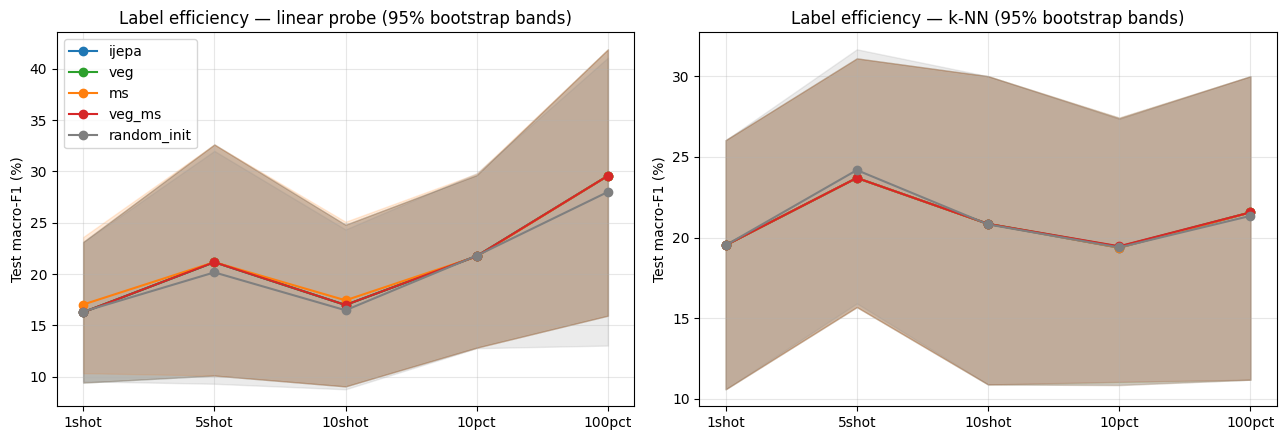

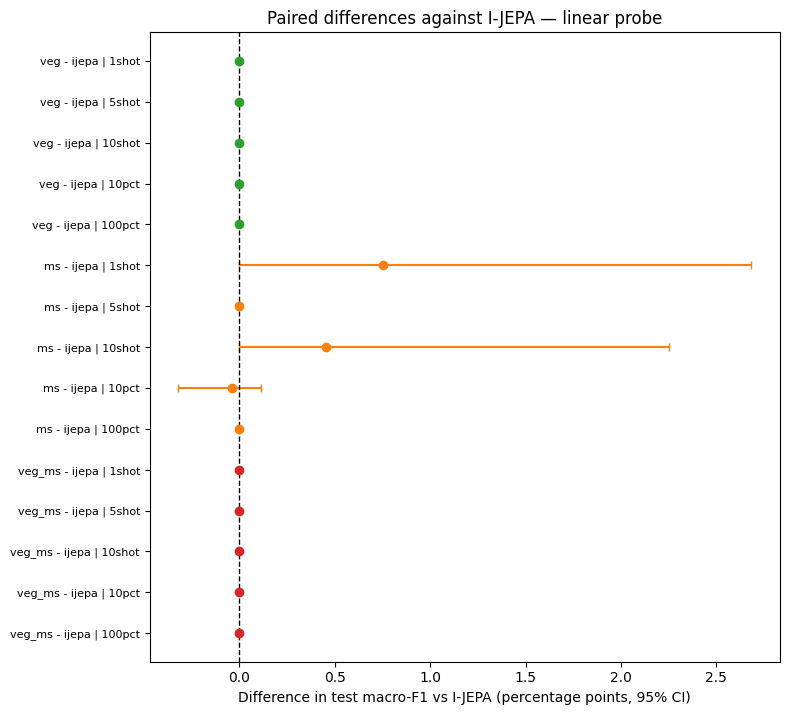

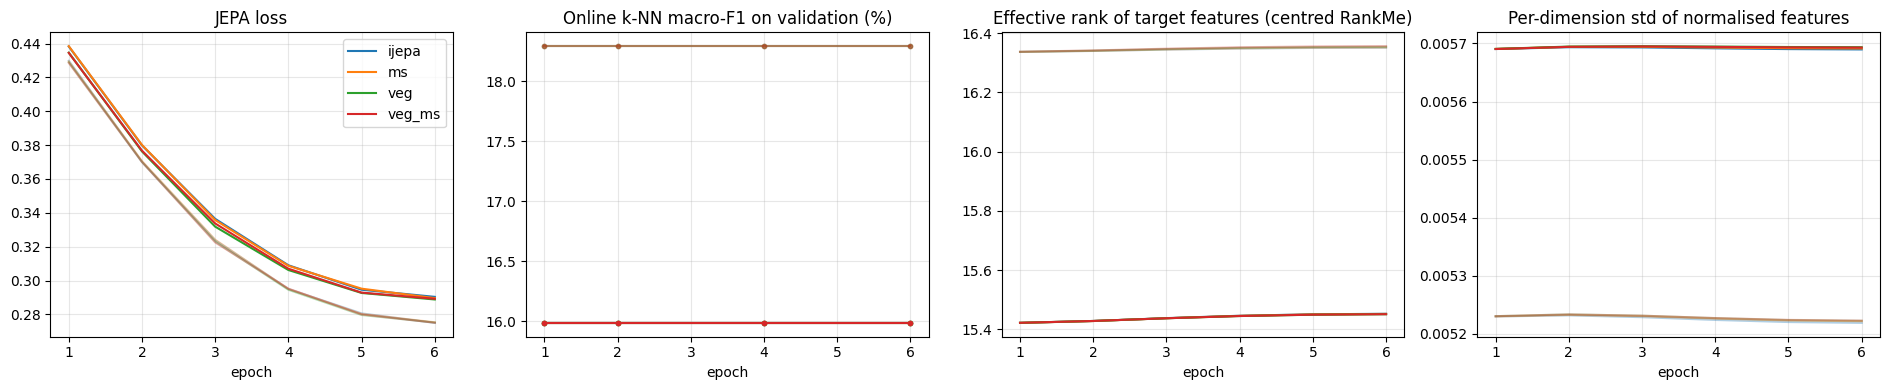

Mean tokens per image (target tokens should be similar across arms; context differs when targets overlap):


,ctx_tokens,tgt_tokens
arm,,
ijepa,19.8,44.6
veg,23.0,44.6
ms,20.0,44.8
veg_ms,22.3,44.8


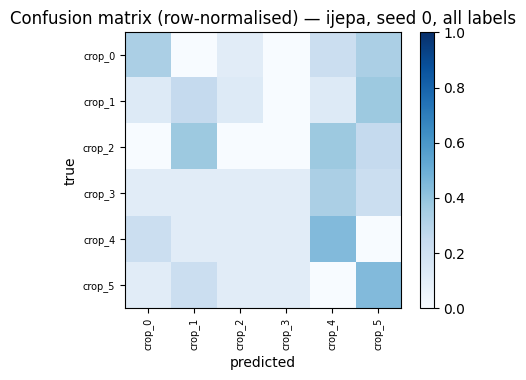

In [17]:
def arm_ci(arm, ev, regime, B=300):
    return bootstrap_stat([arm], ev, regime, lambda f: f[arm], B=B)


if len(RES):
    colors = {"ijepa": "#1f77b4", "veg": "#2ca02c", "ms": "#ff7f0e", "veg_ms": "#d62728", "random_init": "#7f7f7f",
              "dinov2": "#9467bd", "supervised": "#8c564b"}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, ev in zip(axes, ["probe", "knn"]):
        for arm in [a for a in ARM_ORDER if a != "supervised"]:
            xs, ys, lo, hi = [], [], [], []
            for j, regime in enumerate(REGIMES):
                r = arm_ci(arm, ev, regime)
                if r:
                    xs.append(j); ys.append(100 * r["point"]); lo.append(100 * r["lo"]); hi.append(100 * r["hi"])
            if xs:
                ax.plot(xs, ys, marker="o", label=arm, color=colors.get(arm))
                ax.fill_between(xs, lo, hi, alpha=0.15, color=colors.get(arm))
        ax.set_xticks(range(len(REGIMES)))
        ax.set_xticklabels(REGIMES)
        ax.set_ylabel("Test macro-F1 (%)")
        ax.set_title(f"Label efficiency — {'linear probe' if ev == 'probe' else 'k-NN'} (95% bootstrap bands)")
        ax.grid(alpha=0.3)
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(OUT / "figures" / "label_efficiency.png", dpi=150)
    plt.show()

if not COMP.empty:
    sub = COMP[(COMP["eval"] == "probe") & COMP["comparison"].str.endswith("- ijepa")]
    comps = list(dict.fromkeys(sub["comparison"]))
    fig, ax = plt.subplots(figsize=(8, 0.5 + 0.45 * len(sub)))
    yl, y = [], 0
    for cname in comps:
        for _, r in sub[sub["comparison"] == cname].iterrows():
            ax.errorbar(r["diff_pp"], y, xerr=[[r["diff_pp"] - r["ci_lo_pp"]], [r["ci_hi_pp"] - r["diff_pp"]]], fmt="o",
                        color=colors.get(cname.split(" - ")[0]), capsize=3)
            yl.append(f"{cname} | {r['regime']}")
            y += 1
    ax.axvline(0, color="k", lw=1, ls="--")
    ax.set_yticks(range(len(yl)))
    ax.set_yticklabels(yl, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Difference in test macro-F1 vs I-JEPA (percentage points, 95% CI)")
    ax.set_title("Paired differences against I-JEPA — linear probe")
    plt.tight_layout()
    plt.savefig(OUT / "figures" / "paired_differences.png", dpi=150)
    plt.show()

logs = []
for f in sorted((OUT / "runs").glob("*/train_log.csv")):
    d = pd.read_csv(f)
    d["run"] = f.parent.name
    d["arm"], d["seed"] = f.parent.name.rsplit("_s", 1)[0], int(f.parent.name.rsplit("_s", 1)[1])
    logs.append(d)
if logs:
    L = pd.concat(logs)
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    for (arm, seed), d in L.groupby(["arm", "seed"]):
        kw = dict(color=colors.get(arm), alpha=1.0 if seed == min(SEEDS_RUN) else 0.35, label=arm if seed == min(SEEDS_RUN) else None)
        axes[0].plot(d["epoch"], d["loss"], **kw)
        dk = d.dropna(subset=["knn_val_f1"])
        axes[1].plot(dk["epoch"], 100 * dk["knn_val_f1"], marker=".", **kw)
        axes[2].plot(d["epoch"], d["rankme"], **kw)
        axes[3].plot(d["epoch"], d["feat_std"], **kw)
    axes = [axes[0], axes[1], axes[2], axes[3]]
    for ax, t in zip(axes, ["JEPA loss", "Online k-NN macro-F1 on validation (%)", "Effective rank of target features (centred RankMe)",
                            "Per-dimension std of normalised features"]):
        ax.set_title(t)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(OUT / "figures" / "training_curves.png", dpi=150)
    plt.show()
    tok = L.groupby("arm")[["ctx_tokens", "tgt_tokens"]].mean().reindex([a for a in ARMS if a in set(L["arm"])])
    print("Mean tokens per image (target tokens should be similar across arms; context differs when targets overlap):")
    display(tok.round(1))
    tok.to_csv(OUT / "stats" / "token_budget.csv")

if len(RES):
    probe100 = RES[(RES["eval"] == "probe") & (RES["regime"] == "100pct")]
    if len(probe100):
        best_arm = probe100.groupby("arm")["macro_f1"].mean().idxmax()
        s0 = sorted(probe100[probe100["arm"] == best_arm]["seed"])[0]
        cm = confusion(Y_TEST, PREDS[(best_arm, "probe", "100pct", s0, 0)], K)
        cmn = cm / np.maximum(1, cm.sum(1, keepdims=True))
        fig, ax = plt.subplots(figsize=(min(14, 2 + 0.45 * K), min(12, 1.5 + 0.4 * K)))
        im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(K)); ax.set_yticks(range(K))
        ax.set_xticklabels(CLASSES, rotation=90, fontsize=7); ax.set_yticklabels(CLASSES, fontsize=7)
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.set_title(f"Confusion matrix (row-normalised) — {best_arm}, seed {s0}, all labels")
        plt.colorbar(im, ax=ax, fraction=0.046)
        plt.tight_layout()
        plt.savefig(OUT / "figures" / "confusion_best_arm.png", dpi=150)
        plt.show()

## 15. Package the results
Writes `results_bundle.zip` (configs, logs, results, statistics, figures, splits — no image cache, and no checkpoints
unless `ZIP_CHECKPOINTS = True`). On Kaggle, everything in `/kaggle/working` is kept with the saved notebook version.

In [18]:
bundle = OUT / "results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob("*"):
        if not f.is_file() or f == bundle or "cache" in f.parts or "synthetic_data" in f.parts:
            continue
        if f.suffix == ".pt" and not ZIP_CHECKPOINTS:
            continue
        z.write(f, f.relative_to(OUT))
size_mb = bundle.stat().st_size / 1e6
done = len(list((OUT / "runs").glob("*/eval.json")))
print(f"Bundle: {bundle} ({size_mb:.1f} MB) | finished queue items: {done}/{len(build_queue())} on this shard")
print(f"Session time used: {(time.time() - SESSION_START) / 3600:.2f} h")

Bundle: outputs\smoke\results_bundle.zip (0.4 MB) | finished queue items: 12/12 on this shard
Session time used: 0.02 h
